In [1]:
# [Setup] Import library utama
import os, glob, time, warnings
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from scipy.stats import ks_2samp, spearmanr
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from IPython.display import display

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_columns', 120)

In [2]:
# [Setup] Cetak versi library untuk reproduksibilitas
import sys, scipy, sklearn
print('python', sys.version.split()[0])
for m in (np, pd, scipy, sklearn, lgb):
    print(m.__name__, m.__version__)

python 3.13.15
numpy 2.1.3
pandas 2.3.3
scipy 1.16.3
sklearn 1.6.1
lightgbm 4.6.0


In [3]:
# [Setup] Konfigurasi: path, seed, parameter LightGBM, flag cache dan audit
DATA_DIR = os.environ.get('DATA_DIR')    # None = cari otomatis, atau isi path folder data
ART_DIR, SUB_DIR = 'artifacts', 'submissions'

FEATURE_VERSION = 'v0'
USE_CACHE = False                        # False = fitur selalu dibangun dari nol (untuk run final)
FEATURE_PATH = f'{ART_DIR}/features_{FEATURE_VERSION}.parquet'

EXP_NAME = 'lgbm_final'
SEED = 42
N_FOLDS = 5
BASE_DROP = ['customer_id', 'is_train', 'target', 'decision_datetime']
EXTRA_DROP = []

LGB_PARAMS = dict(
    objective='binary', n_estimators=5000, learning_rate=0.03,
    num_leaves=31, min_child_samples=50, subsample=0.8, subsample_freq=1,
    colsample_bytree=0.7, reg_lambda=5.0, n_jobs=-1, verbose=-1,
    deterministic=True, force_row_wise=True,
)
EARLY_STOP = 200

USE_V1 = True                            # True = pakai fitur v1 (ecommerce, bureau, repayment, previous, rasio lintas tabel)
V1_USE = ['ec2_', 'bur2_', 'rep2_', 'prev2_', 'x_']   # grup v1 yang ikut model final (ubah setelah eksperimen)
V1_PATH = f'{ART_DIR}/features_v1.parquet'
NOISE_GROUPS = ('account', 'account_3m', 'repayment_6m', 'flags')   # grup tanpa kontribusi pada ablasi
NOISE_COLS = ['term_months', 'has_bur', 'has_ec']                  # kolom konstan
RUN_V1_EXPERIMENTS = True                # False = lewati perbandingan varian fitur (lama)
V1_SEEDS = (42, 43, 44)                  # seed untuk CV berulang (paired)
RUN_IMPORTANCE = True                     # False = lewati analisis pengaruh fitur (permutation, SHAP, ablasi)
RUN_AUDIT = True                         # False = lewati audit yang melatih model (lebih cepat)

np.random.seed(SEED)
for d in (ART_DIR, SUB_DIR):
    os.makedirs(d, exist_ok=True)

In [4]:
# [Data] Fungsi pencari folder data otomatis
def find_data_dir():
    for root in ['.', 'data', '/kaggle/input', '/content']:
        hits = glob.glob(os.path.join(root, '**', 'train_applications.csv'), recursive=True)
        if hits:
            return os.path.dirname(hits[0])
    raise FileNotFoundError('train_applications.csv tidak ditemukan. Isi DATA_DIR di config.')

In [5]:
# [Data] Daftar kolom datetime per tabel
APP_DT = ['application_datetime', 'decision_datetime']
DT_COLS = {
    'train_applications': APP_DT,
    'test_applications': APP_DT,
    'customer_profiles': [],
    'previous_applications': APP_DT,
    'repayment_history': ['due_date', 'last_payment_datetime'],
    'account_behavior': ['month'],
    'bureau_observations': ['report_datetime', 'available_datetime'],
    'ecommerce_transactions': ['transaction_datetime'],
}

In [6]:
# [Data] Load 8 tabel dan sample_submission
DATA_DIR = DATA_DIR or find_data_dir()
print('DATA_DIR =', DATA_DIR)
T = {n: pd.read_csv(os.path.join(DATA_DIR, f'{n}.csv'), parse_dates=c) for n, c in DT_COLS.items()}
SUB = pd.read_csv(os.path.join(DATA_DIR, 'sample_submission.csv'))
tr, te, prof = T['train_applications'], T['test_applications'], T['customer_profiles']

DATA_DIR = /kaggle/input/competitions/data-science-competition-logika-ui-2026


In [7]:
# [Data] Ringkasan ukuran, missing, dan duplikasi tiap tabel
summary = pd.DataFrame({
    n: {'baris': len(d), 'kolom': d.shape[1],
        'missing_%': round(d.isna().mean().mean() * 100, 2),
        'baris_duplikat': int(d.duplicated().sum())}
    for n, d in T.items()}).T
display(summary)

,baris,kolom,missing_%,baris_duplikat
train_applications,70000.0,10.0,0.00,0.0
test_applications,30000.0,9.0,0.00,0.0
customer_profiles,100000.0,8.0,0.00,0.0
previous_applications,201984.0,11.0,7.68,0.0
repayment_history,1361341.0,9.0,0.26,0.0
account_behavior,1084418.0,10.0,0.00,0.0
bureau_observations,797563.0,14.0,4.62,0.0
ecommerce_transactions,4359817.0,10.0,0.00,0.0


In [8]:
# [Data] Cek integritas ID dan kecocokan train/test/profil
checks = {
    'application_id unik (train)': tr.application_id.is_unique,
    'application_id unik (test)': te.application_id.is_unique,
    'tidak ada ID train yang muncul di test': not (set(tr.application_id) & set(te.application_id)),
    'customer_id unik (profiles)': prof.customer_id.is_unique,
    'ID test == ID sample_submission': set(te.application_id) == set(SUB.application_id),
    'semua customer train punya profil': bool(tr.customer_id.isin(prof.customer_id).all()),
    'semua customer test punya profil': bool(te.customer_id.isin(prof.customer_id).all()),
}
display(pd.Series(checks, name='lolos').to_frame())

,lolos
application_id unik (train),True
application_id unik (test),True
tidak ada ID train yang muncul di test,True
customer_id unik (profiles),True
ID test == ID sample_submission,True
semua customer train punya profil,True
semua customer test punya profil,True


Target rate train : 13.5814%  (n=70,000, positif=9,507)
Train decision    : 2025-01-01 08:00:00 -> 2025-12-28 20:59:00
Test  decision    : 2025-01-01 08:07:00 -> 2025-12-28 20:52:00
Customer test yang juga ada di train: 0.00%
Aplikasi per customer (train): {'mean': 1.0, 'max': 1.0}


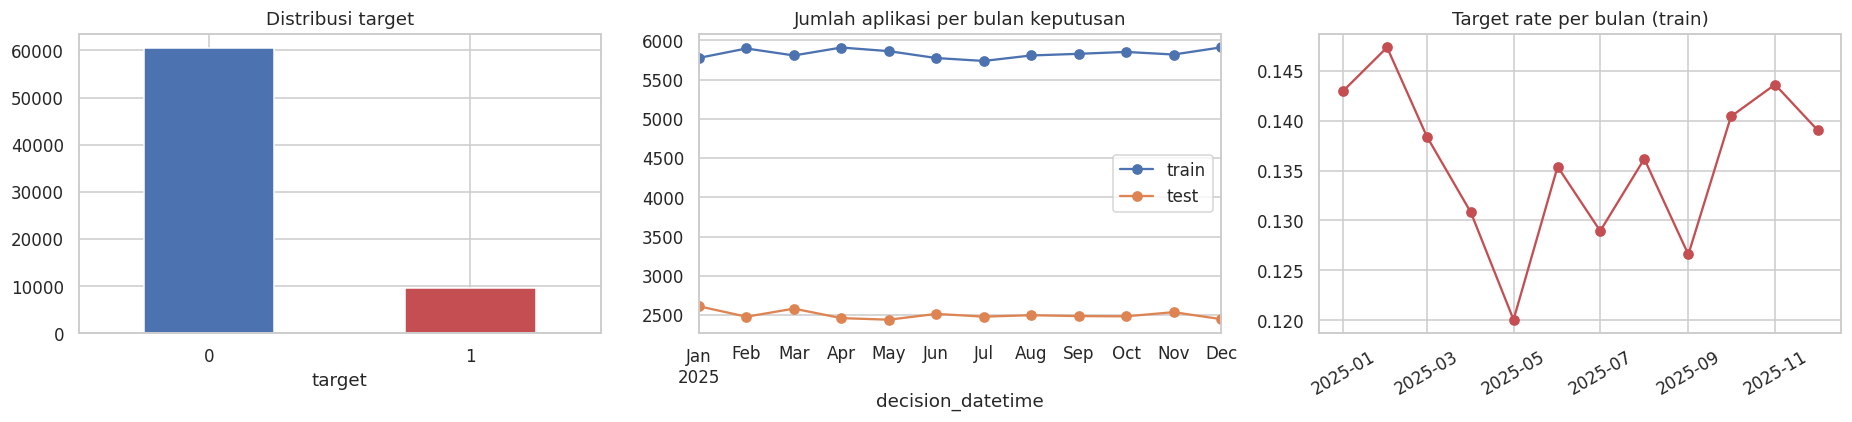

In [9]:
# [EDA] Target dan waktu: target rate, rentang keputusan, overlap customer
print(f'Target rate train : {tr.target.mean():.4%}  (n={len(tr):,}, positif={tr.target.sum():,})')
print('Train decision    :', tr.decision_datetime.min(), '->', tr.decision_datetime.max())
print('Test  decision    :', te.decision_datetime.min(), '->', te.decision_datetime.max())
print(f'Customer test yang juga ada di train: {te.customer_id.isin(tr.customer_id).mean():.2%}')
print('Aplikasi per customer (train):', tr.groupby('customer_id').size().agg(['mean', 'max']).round(2).to_dict())

mon = lambda s: s.dt.to_period('M').dt.to_timestamp()
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
tr.target.value_counts().sort_index().plot.bar(ax=ax[0], color=['#4C72B0', '#C44E52'])
ax[0].set_title('Distribusi target'); ax[0].tick_params(axis='x', rotation=0)
for d, lbl in [(tr, 'train'), (te, 'test')]:
    mon(d.decision_datetime).value_counts().sort_index().plot(ax=ax[1], label=lbl, marker='o')
ax[1].set_title('Jumlah aplikasi per bulan keputusan'); ax[1].legend()
mt = tr.groupby(mon(tr.decision_datetime)).target.mean()
ax[2].plot(mt.index, mt.values, marker='o', color='#C44E52')
ax[2].set_title('Target rate per bulan (train)'); ax[2].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

In [10]:
# [EDA] Gabungkan train dan test (ALL) untuk pembuatan fitur
ALL = pd.concat([tr.assign(is_train=1), te.assign(is_train=0)], ignore_index=True)

In [11]:
# [EDA] Fungsi hitung porsi baris yang melewati cutoff
def future_share(tbl, tcol, key='customer_id'):
    a = ALL[list(dict.fromkeys(['application_id', key, 'decision_datetime']))] \
        .rename(columns={'decision_datetime': 'cutoff'})
    t = tbl[list(dict.fromkeys([key, tcol]))]
    m = a.merge(t, on=key)
    return pd.Series({'baris_setelah_cutoff_%': round((m[tcol] >= m['cutoff']).mean() * 100, 2),
                      'baris_join': len(m)})

In [12]:
# [EDA] Audit baris setelah cutoff di tiap tabel historis
acc = T['account_behavior'].assign(month_end=lambda d: d['month'] + pd.offsets.MonthBegin(1))
audit = pd.DataFrame({
    'previous_applications.decision_datetime': future_share(T['previous_applications'], 'decision_datetime'),
    'repayment_history.due_date': future_share(T['repayment_history'], 'due_date'),
    'repayment_history.last_payment_datetime': future_share(T['repayment_history'], 'last_payment_datetime'),
    'account_behavior.month_end': future_share(acc, 'month_end'),
    'bureau.report_datetime': future_share(T['bureau_observations'], 'report_datetime', 'application_id'),
    'bureau.available_datetime': future_share(T['bureau_observations'], 'available_datetime', 'application_id'),
    'ecommerce.transaction_datetime': future_share(T['ecommerce_transactions'], 'transaction_datetime'),
}).T
display(audit)

,baris_setelah_cutoff_%,baris_join
previous_applications.decision_datetime,0.0,201984.0
repayment_history.due_date,0.0,1361341.0
repayment_history.last_payment_datetime,0.0,1361341.0
account_behavior.month_end,0.0,1084418.0
bureau.report_datetime,0.0,264088.0
bureau.available_datetime,0.0,264088.0
ecommerce.transaction_datetime,0.0,4359817.0


In [13]:
# [Fitur] Fungsi filter waktu: join lalu ambil baris sebelum cutoff
def join_before(A, tbl, tcol, key='customer_id', le=False):
    a = A[list(dict.fromkeys(['application_id', key, 'decision_datetime']))] \
        .rename(columns={'decision_datetime': 'cutoff'})
    t = tbl.drop(columns=[c for c in ['application_id', 'customer_id'] if c in tbl.columns and c != key])
    m = a.merge(t, on=key, how='inner')
    keep = (m[tcol] <= m['cutoff']) if le else (m[tcol] < m['cutoff'])
    return m[keep]

In [14]:
# [Fitur] Modul aplikasi + profil
def f_base(A, prof):
    d = A.merge(prof, on='customer_id', how='left')
    inc = d.declared_monthly_income.replace(0, np.nan)
    d['inst_to_income'] = d.proposed_monthly_installment / inc
    d['loan_to_annual_income'] = d.loan_amount / (inc * 12)
    d['total_repay'] = d.proposed_monthly_installment * d.term_months
    d['interest_burden'] = d.total_repay / d.loan_amount - 1
    d['income_per_dependent'] = d.declared_monthly_income / (d.dependents + 1)
    d['tenure_years'] = d.employment_tenure_months / 12
    d['decision_lag_h'] = (d.decision_datetime - d.application_datetime).dt.total_seconds() / 3600
    d['dec_dow'] = d.decision_datetime.dt.dayofweek
    d['dec_hour'] = d.decision_datetime.dt.hour
    cols = ['application_id', 'loan_amount', 'term_months', 'annual_interest_rate',
            'proposed_monthly_installment', 'loan_purpose', 'age', 'region', 'employment_type',
            'employment_tenure_months', 'declared_monthly_income', 'dependents', 'housing_status',
            'inst_to_income', 'loan_to_annual_income', 'total_repay', 'interest_burden',
            'income_per_dependent', 'tenure_years', 'decision_lag_h', 'dec_dow', 'dec_hour']
    return d[cols].set_index('application_id')

In [15]:
# [Fitur] Modul previous_applications
def f_previous(A, P):
    m = join_before(A, P, 'decision_datetime')
    m = m.assign(is_appr=(m.decision == 'approved').astype(int),
                 is_rej=(m.decision == 'rejected').astype(int),
                 is_can=(m.decision == 'cancelled').astype(int),
                 days_since=(m.cutoff - m.decision_datetime).dt.days)
    out = m.groupby('application_id').agg(
        prev_cnt=('decision', 'size'), prev_cnt_appr=('is_appr', 'sum'),
        prev_cnt_rej=('is_rej', 'sum'), prev_cnt_can=('is_can', 'sum'),
        prev_req_mean=('requested_amount', 'mean'), prev_appr_max=('approved_amount', 'max'),
        prev_appr_sum=('approved_amount', 'sum'), prev_rate_mean=('annual_interest_rate', 'mean'),
        prev_inst_mean=('scheduled_monthly_installment', 'mean'), prev_last_gap_days=('days_since', 'min'))
    out['prev_rej_ratio'] = out.prev_cnt_rej / out.prev_cnt
    out['prev_appr_ratio'] = out.prev_cnt_appr / out.prev_cnt
    return out

In [16]:
# [Fitur] Modul repayment_history
def f_repay(A, R):
    m = join_before(A, R, 'due_date')
    m = m.assign(late=(m.max_days_past_due > 0).astype(int),
                 late30=(m.max_days_past_due >= 30).astype(int),
                 late60=(m.max_days_past_due >= 60).astype(int),
                 late90=(m.max_days_past_due >= 90).astype(int),
                 paid_ratio=m.amount_paid / m.amount_due.replace(0, np.nan),
                 unpaid=(m.amount_paid < m.amount_due).astype(int),
                 days_since_due=(m.cutoff - m.due_date).dt.days)
    def block(d, p):
        return d.groupby('application_id').agg(**{
            f'{p}_cnt_inst': ('installment_id', 'size'), f'{p}_max_dpd': ('max_days_past_due', 'max'),
            f'{p}_mean_dpd': ('max_days_past_due', 'mean'), f'{p}_late_ratio': ('late', 'mean'),
            f'{p}_late30_ratio': ('late30', 'mean'), f'{p}_late60_ratio': ('late60', 'mean'),
            f'{p}_late90_ratio': ('late90', 'mean'), f'{p}_paid_ratio': ('paid_ratio', 'mean'),
            f'{p}_unpaid_ratio': ('unpaid', 'mean')})
    out = block(m, 'rep').join(block(m[m.days_since_due <= 180], 'rep6'))
    g = m.groupby('application_id')
    out['rep_cnt_loans'] = g['loan_id'].nunique()
    out['rep_due_sum'] = g['amount_due'].sum()
    out['rep_last_gap_days'] = g['days_since_due'].min()
    return out

In [17]:
# [Fitur] Modul account_behavior
def f_account(A, B):
    B = B.assign(month_end=B['month'] + pd.offsets.MonthBegin(1))
    m = join_before(A, B, 'month_end', le=True)          # hanya bulan yang sudah selesai
    m = m.assign(months_ago=(m.cutoff.dt.year - m.month.dt.year) * 12 + (m.cutoff.dt.month - m.month.dt.month),
                 net_flow=m.inflows - m.outflows,
                 out_in_ratio=m.outflows / m.inflows.replace(0, np.nan))
    def block(d, p):
        return d.groupby('application_id').agg(**{
            f'{p}_cnt_months': ('month', 'size'), f'{p}_avg_bal': ('average_balance', 'mean'),
            f'{p}_min_bal': ('minimum_balance', 'min'), f'{p}_low_days': ('low_balance_days', 'mean'),
            f'{p}_inflow': ('inflows', 'mean'), f'{p}_inflow_std': ('inflows', 'std'),
            f'{p}_outflow': ('outflows', 'mean'), f'{p}_income_cr': ('income_like_credits', 'mean'),
            f'{p}_net_flow': ('net_flow', 'mean'), f'{p}_out_in': ('out_in_ratio', 'mean')})
    out = block(m, 'acc').join(block(m[m.months_ago <= 3], 'acc3'))
    out['acc_bal_trend'] = out.acc3_avg_bal / out.acc_avg_bal.replace(0, np.nan)
    return out

In [18]:
# [Fitur] Modul bureau_observations
def f_bureau(A, U):
    m = join_before(A, U, 'available_datetime', key='application_id', le=True)
    # laporan terbaru yang sudah tersedia per provider
    m = m.sort_values('report_datetime').groupby(['application_id', 'bureau_provider']).tail(1)
    out = m.groupby('application_id').agg(
        bur_cnt_reports=('bureau_provider', 'size'), bur_score_mean=('score', 'mean'),
        bur_score_min=('score', 'min'), bur_score_max=('score', 'max'),
        bur_active=('active_accounts', 'sum'), bur_outstanding=('outstanding_balance', 'sum'),
        bur_rev_limit=('revolving_credit_limit', 'sum'), bur_rev_out=('revolving_outstanding_balance', 'sum'),
        bur_util_mean=('utilization', 'mean'), bur_util_max=('utilization', 'max'),
        bur_inq=('inquiries_last_6m', 'sum'), bur_inq_max=('inquiries_last_6m', 'max'),
        bur_delinq=('delinquent_accounts_last_12m', 'sum'), bur_delinq_max=('delinquent_accounts_last_12m', 'max'))
    out['bur_util_total'] = out.bur_rev_out / out.bur_rev_limit.replace(0, np.nan)
    out['bur_score_missing_share'] = m['score'].isna().groupby(m['application_id']).mean()
    return out

In [19]:
# [Fitur] Modul ecommerce_transactions
PM = ['COD', 'e_wallet', 'bank_transfer', 'debit_card', 'credit_card']
def f_ecom(A, E):
    m = join_before(A, E, 'transaction_datetime')
    m = m.assign(days_since=(m.cutoff - m.transaction_datetime).dt.days)
    o = m.drop_duplicates(['application_id', 'order_id']).copy()     # deduplikasi order_total
    o['cancel'] = (o.order_status == 'cancelled').astype(int)
    o['spend'] = np.where(o.order_status == 'completed', o.order_total, 0)
    o['spend_90d'] = np.where(o.days_since <= 90, o.spend, 0)
    for k in PM:
        o[f'pm_{k}'] = (o.payment_method == k).astype(int)
    out = o.groupby('application_id').agg(
        ec_cnt_orders=('order_id', 'size'), ec_cancel_ratio=('cancel', 'mean'),
        ec_spend_total=('spend', 'sum'), ec_spend_90d=('spend_90d', 'sum'),
        ec_order_mean=('spend', 'mean'), ec_last_gap_days=('days_since', 'min'),
        **{f'ec_pm_{k}': (f'pm_{k}', 'mean') for k in PM})
    ic = m[m.order_status == 'completed']                              # kategori hanya dari order selesai
    cat = ic.pivot_table(index='application_id', columns='product_category',
                         values='item_total', aggfunc='sum', fill_value=0)
    cat = cat.div(cat.sum(axis=1).replace(0, np.nan), axis=0).add_prefix('ec_share_')
    return out.join(cat)

In [20]:
# [Fitur] Perakitan semua modul menjadi tabel fitur FE
FIRST_COL = {'prev': 'prev_cnt', 'rep': 'rep_cnt_inst', 'acc': 'acc_cnt_months',
             'bur': 'bur_cnt_reports', 'ec': 'ec_cnt_orders'}
CAT_COLS = ['loan_purpose', 'region', 'employment_type', 'housing_status']


def assemble_features(ALL, T):
    mods = {
        'prev': f_previous(ALL, T['previous_applications']),
        'rep':  f_repay(ALL, T['repayment_history']),
        'acc':  f_account(ALL, T['account_behavior']),
        'bur':  f_bureau(ALL, T['bureau_observations']),
        'ec':   f_ecom(ALL, T['ecommerce_transactions']),
    }
    FE = ALL.set_index('application_id')[['customer_id', 'is_train', 'target', 'decision_datetime']] \
            .join(f_base(ALL, T['customer_profiles']))
    for p, mod in mods.items():
        FE = FE.join(mod, how='left')
        FE[f'has_{p}'] = FE[FIRST_COL[p]].notna().astype(int)      # flag: punya riwayat atau tidak
    cnt_cols = [c for c in FE.columns if '_cnt' in c]
    FE[cnt_cols] = FE[cnt_cols].fillna(0)
    for c in CAT_COLS:
        FE[c] = FE[c].astype('category')
    return FE

In [21]:
# [Fitur] Fungsi simpan dan muat cache fitur
def save_features(FE, path):
    try:
        FE.to_parquet(path)
    except Exception as e:
        path = path.rsplit('.', 1)[0] + '.pkl'
        FE.to_pickle(path); print('parquet gagal, pakai pickle:', e)
    return path


def load_features(path):
    if os.path.exists(path):
        return pd.read_parquet(path)
    alt = path.rsplit('.', 1)[0] + '.pkl'
    return pd.read_pickle(alt) if os.path.exists(alt) else None

In [22]:
# [Fitur] Bangun FE (atau muat dari cache) dan simpan
FE = load_features(FEATURE_PATH) if USE_CACHE else None
if FE is None:
    t0 = time.time()
    FE = assemble_features(ALL, T)
    print('disimpan ke', save_features(FE, FEATURE_PATH), f'({time.time()-t0:.0f}s)')
else:
    print('Memakai cache:', FEATURE_PATH)
print('Shape FE:', FE.shape)
display(FE.head())

disimpan ke artifacts/features_v0.parquet (21s)
Shape FE: (100000, 118)


,customer_id,is_train,target,decision_datetime,loan_amount,term_months,annual_interest_rate,proposed_monthly_installment,loan_purpose,age,region,employment_type,employment_tenure_months,declared_monthly_income,dependents,housing_status,inst_to_income,loan_to_annual_income,total_repay,interest_burden,income_per_dependent,tenure_years,decision_lag_h,dec_dow,dec_hour,prev_cnt,prev_cnt_appr,prev_cnt_rej,prev_cnt_can,prev_req_mean,prev_appr_max,prev_appr_sum,prev_rate_mean,prev_inst_mean,prev_last_gap_days,prev_rej_ratio,prev_appr_ratio,has_prev,rep_cnt_inst,rep_max_dpd,rep_mean_dpd,rep_late_ratio,rep_late30_ratio,rep_late60_ratio,rep_late90_ratio,rep_paid_ratio,rep_unpaid_ratio,rep6_cnt_inst,rep6_max_dpd,rep6_mean_dpd,rep6_late_ratio,rep6_late30_ratio,rep6_late60_ratio,rep6_late90_ratio,rep6_paid_ratio,rep6_unpaid_ratio,rep_cnt_loans,rep_due_sum,rep_last_gap_days,has_rep,acc_cnt_months,acc_avg_bal,acc_min_bal,acc_low_days,acc_inflow,acc_inflow_std,acc_outflow,acc_income_cr,acc_net_flow,acc_out_in,acc3_cnt_months,acc3_avg_bal,acc3_min_bal,acc3_low_days,acc3_inflow,acc3_inflow_std,acc3_outflow,acc3_income_cr,acc3_net_flow,acc3_out_in,acc_bal_trend,has_acc,bur_cnt_reports,bur_score_mean,bur_score_min,bur_score_max,bur_active,bur_outstanding,bur_rev_limit,bur_rev_out,bur_util_mean,bur_util_max,bur_inq,bur_inq_max,bur_delinq,bur_delinq_max,bur_util_total,bur_score_missing_share,has_bur,ec_cnt_orders,ec_cancel_ratio,ec_spend_total,ec_spend_90d,ec_order_mean,ec_last_gap_days,ec_pm_COD,ec_pm_e_wallet,ec_pm_bank_transfer,ec_pm_debit_card,ec_pm_credit_card,ec_share_education,ec_share_electronics,ec_share_fashion,ec_share_groceries,ec_share_health,ec_share_home,ec_share_personal_care,has_ec
application_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
A_683e78eb3ac9de85,C_e8cf5a68cbe13bf2,1,0.0,2025-01-14 10:01:00,26500000,12,0.24,2505830,education,39,Region_D,self_employed,36,9388746,2,rented,0.266897,0.235211,30069960,0.134715,3129582.0,3.000000,2.950833,1,10,3.0,1.0,2.0,0.0,2.256667e+07,32700000.0,32700000.0,0.240,5.837795e+06,130.0,0.666667,0.333333,1,6.0,30.0,9.833333,0.333333,0.166667,0.000000,0.000000,1.000000,0.000000,4.0,29.0,7.250000,0.25,0.000000,0.000000,0.0,1.000000,0.000000,1.0,35026764.0,79.0,1,8.0,3.421229e+07,29269771.0,0.0,8.515472e+06,1.633496e+06,7.522494e+06,5.593567e+06,9.929784e+05,0.909341,3.0,3.389662e+07,29772421.0,0.0,7.620703e+06,1.560473e+06,6.476239e+06,5.833847e+06,1.144464e+06,0.828796,0.990773,1,2,620.500000,615.0,626.0,4,44534242,0,0,NaN,NaN,6,4,1,1,NaN,0.0,1,48,0.000000,11694000,3332000,243625.000000,6,0.000000,0.458333,0.541667,0.000000,0.0,0.107063,0.145887,0.064050,0.088250,0.135369,0.192834,0.266547,1
A_062a340ac8976ccf,C_98f51064dd87311a,1,0.0,2025-07-03 15:43:00,52200000,12,0.24,4936011,home_improvement,38,Region_C,variable_income,26,11535405,0,family,0.427901,0.377100,59232132,0.134715,11535405.0,2.166667,27.869722,3,15,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,3,644.666667,623.0,671.0,3,52777904,0,0,NaN,NaN,4,2,0,0,NaN,0.0,1,54,0.055556,17993000,5052000,333203.703704,6,0.814815,0.000000,0.000000,0.185185,0.0,0.108820,0.095537,0.066637,0.142555,0.092703,0.323626,0.170122,1
A_6a8b16ffd23c230b,C_2adbcbacbfe76bda,1,0.0,2025-03-11 20:14:00,40300000,12,0.32,3968484,household,48,Region_A,variable_income,41,12684538,0,rented,0.312860,0.264758,47621808,0.181683,12684538.0,3.416667,93.846111,1,20,7.0,5.0,2.0,0.0,3.795714e+07,61900000.0,188200000.0,0.248,4.060959e+06,59.0,0.285714,0.714286,1,50.0,183.0,47.000000,0.680000,0.580000,0.400000,0.240000,0.863481,0.160000,20.0,122.0,55.850000,0.85,0.700000,0.550000,0.3,0.658702,0.400000,5.0,192309960.0,11.0,1,16.0,7.775065e+07,41975918.0,0.0,1.880741e+07,7.634869e+06,1.633923e+07,1.192489e+07,2.468186e+06,0.917460,3.0,8.

In [23]:
# [Fitur v1] E-commerce: pesanan selesai vs batal, jendela waktu, kategori, interval antar-order
def f_ecom_v1(A, E):
    m = join_before(A, E, 'transaction_datetime')
    m['days_since'] = (m.cutoff - m.transaction_datetime).dt.days
    m['done'] = m.order_status == 'completed'
    o = m.drop_duplicates(['application_id', 'order_id'])                 # satu baris per order
    oc, ox = o[o.done], o[~o.done]
    ga, gc, gx = o.groupby('application_id'), oc.groupby('application_id'), ox.groupby('application_id')

    out = pd.DataFrame(index=ga.size().index)
    out['ec2_cnt_done'], out['ec2_cnt_cancel'] = gc.size(), gx.size()
    n_d, n_c = out.ec2_cnt_done.fillna(0), out.ec2_cnt_cancel.fillna(0)
    out['ec2_cancel_ratio'] = n_c / (n_d + n_c)
    out['ec2_done_mean'], out['ec2_done_median'] = gc['order_total'].mean(), gc['order_total'].median()
    out['ec2_done_max'], out['ec2_done_std'] = gc['order_total'].max(), gc['order_total'].std()
    out['ec2_cancel_mean'] = gx['order_total'].mean()
    out['ec2_cancel_value_ratio'] = gx['order_total'].sum() / ga['order_total'].sum()
    out['ec2_sum_done'] = gc['order_total'].sum()
    out['ec2_age_days'] = ga['days_since'].max()
    out['ec2_last_done_gap'], out['ec2_last_cancel_gap'] = gc['days_since'].min(), gx['days_since'].min()

    for w in (30, 90, 180, 365):
        c_w, x_w = oc[oc.days_since <= w].groupby('application_id'), ox[ox.days_since <= w].groupby('application_id')
        out[f'ec2_cnt_done_{w}d'], out[f'ec2_cnt_cancel_{w}d'] = c_w.size(), x_w.size()
        out[f'ec2_sum_done_{w}d'], out[f'ec2_mean_done_{w}d'] = c_w['order_total'].sum(), c_w['order_total'].mean()
        nd, nc = out[f'ec2_cnt_done_{w}d'].fillna(0), out[f'ec2_cnt_cancel_{w}d'].fillna(0)
        out[f'ec2_cancel_ratio_{w}d'] = nc / (nd + nc)
    out['ec2_vel_30_180'] = out.ec2_sum_done_30d.fillna(0) / (out.ec2_sum_done_180d / 6).replace(0, np.nan)
    out['ec2_vel_90_365'] = out.ec2_sum_done_90d.fillna(0) / (out.ec2_sum_done_365d / 4).replace(0, np.nan)

    s = oc.sort_values(['application_id', 'days_since']).copy()
    s['gap'] = s.groupby('application_id')['days_since'].diff()           # jarak antar order selesai
    gg = s.groupby('application_id')['gap']
    out['ec2_gap_mean'], out['ec2_gap_std'], out['ec2_gap_max'] = gg.mean(), gg.std(), gg.max()

    o90 = oc[oc.days_since <= 90]
    for k in PM:
        out[f'ec2_pm90_{k}'] = (o90.payment_method == k).groupby(o90.application_id).mean()

    it = m[m.done].copy()
    it['unit_price'] = it.item_total / it.quantity.replace(0, np.nan)
    gi = it.groupby('application_id')
    out['ec2_unit_price_mean'] = gi['unit_price'].mean()
    out['ec2_items_per_order'] = gi.size() / out.ec2_cnt_done
    cat = it.pivot_table(index='application_id', columns='product_category', values='item_total', aggfunc='sum', fill_value=0)
    share = cat.div(cat.sum(axis=1).replace(0, np.nan), axis=0)
    it90 = it[it.days_since <= 90]
    cat90 = it90.pivot_table(index='application_id', columns='product_category', values='item_total', aggfunc='sum', fill_value=0)
    share90 = cat90.div(cat90.sum(axis=1).replace(0, np.nan), axis=0)
    out = out.join(cat.add_prefix('ec2_sum_cat_')).join(share.add_prefix('ec2_share_cat_')) \
             .join(cat90.add_prefix('ec2_sum90_cat_')).join(share90.add_prefix('ec2_share90_cat_'))
    out['ec2_cat_hhi'] = (share ** 2).sum(axis=1)
    out['ec2_cat_ndistinct'] = (cat > 0).sum(axis=1)
    return out

In [24]:
# [Fitur v1] Bureau: skor per provider (dinormalisasi), selisih antar provider, tren dari laporan lama
BUR_SHORT = {'score': 'score', 'utilization': 'util', 'delinquent_accounts_last_12m': 'delinq',
             'inquiries_last_6m': 'inq', 'outstanding_balance': 'outst'}

def f_bureau_v1(A, U, train_ids):
    # laporan terbaru yang sudah tersedia per provider untuk aplikasi ini
    m = join_before(A, U, 'available_datetime', key='application_id', le=True)
    m = m.sort_values('report_datetime').groupby(['application_id', 'bureau_provider']).tail(1).copy()
    ref = m[m.application_id.isin(train_ids)].groupby('bureau_provider')['score'].agg(['mean', 'std'])   # statistik dari train saja
    m['score_z'] = (m['score'] - m.bureau_provider.map(ref['mean'])) / m.bureau_provider.map(ref['std'])

    wide = m.pivot(index='application_id', columns='bureau_provider', values=list(BUR_SHORT))
    wide.columns = [f'bur2_{BUR_SHORT[f]}_{p[-1]}' for f, p in wide.columns]
    sc = [c for c in wide.columns if c.startswith('bur2_score_')]
    out = wide.copy()
    out['bur2_score_spread'] = wide[sc].max(axis=1) - wide[sc].min(axis=1)
    out['bur2_score_nmiss'] = wide[sc].isna().sum(axis=1)
    gz = m.groupby('application_id')['score_z']
    out['bur2_z_mean'], out['bur2_z_min'], out['bur2_z_max'], out['bur2_z_std'] = gz.mean(), gz.min(), gz.max(), gz.std()

    # laporan lama (aplikasi sebelumnya milik customer yang sama), hanya yang sudah tersedia sebelum cutoff
    a = A[['application_id', 'customer_id', 'decision_datetime']].rename(columns={'decision_datetime': 'cutoff'})
    h = a.merge(U.rename(columns={'application_id': 'src_app'}), on='customer_id')
    h = h[(h.available_datetime <= h.cutoff) & (h.src_app != h.application_id)].copy()
    h['score_z'] = (h['score'] - h.bureau_provider.map(ref['mean'])) / h.bureau_provider.map(ref['std'])
    last_t = h.groupby('application_id')['report_datetime'].transform('max')
    hl = h[h.report_datetime == last_t]
    gh, gl = h.groupby('application_id'), hl.groupby('application_id')
    hist = pd.DataFrame({'bur2_hist_cnt': gh.size(), 'bur2_hist_z_mean': gh['score_z'].mean(),
                         'bur2_hist_z_last': gl['score_z'].mean(), 'bur2_hist_util_mean': gh['utilization'].mean(),
                         'bur2_hist_delinq_max': gh['delinquent_accounts_last_12m'].max()})
    hist['bur2_hist_gap_days'] = (gl['cutoff'].first() - gl['report_datetime'].first()).dt.days
    out = out.join(hist)
    out['bur2_z_delta'] = out.bur2_z_mean - out.bur2_hist_z_last
    out['bur2_util_delta'] = out[[c for c in out.columns if c.startswith('bur2_util_')]].mean(axis=1) - out.bur2_hist_util_mean
    return out

In [25]:
# [Fitur v1] Repayment: status saat cutoff (DPD saat ini, tunggakan), streak, cicilan terakhir, bobot nominal dan recency
def f_repay_v1(A, R_):
    m = join_before(A, R_, 'due_date')
    m = m.assign(late=(m.max_days_past_due > 0).astype(int), cur_late=(m.days_past_due > 0).astype(int),
                 days_since_due=(m.cutoff - m.due_date).dt.days,
                 overdue_amt=np.clip(m.amount_due - m.amount_paid, 0, None))
    m = m.sort_values(['application_id', 'due_date'], ascending=[True, False])
    m['rk'] = m.groupby('application_id').cumcount()                        # 0 = cicilan terbaru
    m['w'] = np.exp(-m.days_since_due / 180)
    m['late_amt'], m['late_rec'] = m.late * m.amount_due, m.late * m.w
    m['streak'] = m.groupby('application_id')['late'].cumprod()           # telat beruntun dari cicilan terbaru
    g = m.groupby('application_id')
    out = pd.DataFrame({
        'rep2_cur_dpd_max': g['days_past_due'].max(), 'rep2_cur_dpd_mean': g['days_past_due'].mean(),
        'rep2_cnt_overdue': g['cur_late'].sum(), 'rep2_sum_overdue_amt': g['overdue_amt'].sum(),
        'rep2_overdue_ratio': g['overdue_amt'].sum() / g['amount_due'].sum(),
        'rep2_late_amt_ratio': g['late_amt'].sum() / g['amount_due'].sum(),
        'rep2_late_rec_ratio': g['late_rec'].sum() / g['w'].sum(),
        'rep2_late_streak': g['streak'].sum(),
    })
    out['rep2_pay_gap_days'] = (g['cutoff'].first() - g['last_payment_datetime'].max()).dt.days
    for n in (3, 6):
        gn = m[m.rk < n].groupby('application_id')
        out[f'rep2_last{n}_late_ratio'], out[f'rep2_last{n}_dpd_max'] = gn['late'].mean(), gn['max_days_past_due'].max()
    pl = m.groupby(['application_id', 'loan_id']).agg(l=('late', 'mean'), mx=('max_days_past_due', 'max'))
    out['rep2_worst_loan_late'] = pl.groupby('application_id')['l'].max()
    out['rep2_cnt_loans_90'] = (pl.mx >= 90).astype(int).groupby('application_id').sum()
    return out

In [26]:
# [Fitur v1] Previous: recency pengajuan, pinjaman aktif, beban kewajiban
def f_previous_v1(A, P):
    m = join_before(A, P, 'decision_datetime')
    m['days_since'] = (m.cutoff - m.decision_datetime).dt.days
    ap = m[m.decision == 'approved'].copy()
    ap['end'] = ap.decision_datetime + pd.to_timedelta(ap.term_months * 30.4, unit='D')
    act = ap[ap.end > ap.cutoff]                                            # pinjaman lama yang masih berjalan saat cutoff
    ga, gact = ap.groupby('application_id'), act.groupby('application_id')
    return pd.DataFrame({
        'prev2_first_gap_days': m.groupby('application_id')['days_since'].max(),
        'prev2_cnt_180d': m[m.days_since <= 180].groupby('application_id').size(),
        'prev2_cnt_365d': m[m.days_since <= 365].groupby('application_id').size(),
        'prev2_last_appr_gap_days': ga['days_since'].min(),
        'prev2_cnt_active': gact.size(),
        'prev2_active_inst_sum': gact['scheduled_monthly_installment'].sum(),
        'prev2_active_amt_sum': gact['approved_amount'].sum(),
        'prev2_appr_amt_max': ga['approved_amount'].max(),
        'prev2_appr_rate_max': ga['annual_interest_rate'].max(),
    })

In [27]:
# [Fitur v1] Perakitan fitur v1 + rasio lintas tabel (prefix x_)
def assemble_v1(FE, ALL, T, train_ids):
    mods = [f_ecom_v1(ALL, T['ecommerce_transactions']), f_bureau_v1(ALL, T['bureau_observations'], train_ids),
            f_repay_v1(ALL, T['repayment_history']), f_previous_v1(ALL, T['previous_applications'])]
    X1 = pd.DataFrame(index=FE.index)
    for mod in mods:
        X1 = X1.join(mod, how='left')
    cnt = [c for c in X1.columns if '_cnt' in c]
    X1[cnt] = X1[cnt].fillna(0)
    inc = FE['declared_monthly_income'].replace(0, np.nan)
    outst = [c for c in X1.columns if c.startswith('bur2_outst_')]
    X1['x_ec90_to_income'] = X1['ec2_sum_done_90d'] / inc
    X1['x_ec90_to_inst'] = X1['ec2_sum_done_90d'] / FE['proposed_monthly_installment'].replace(0, np.nan)
    X1['x_ecmean_to_income'] = X1['ec2_done_mean'] / inc
    X1['x_active_inst_to_income'] = X1['prev2_active_inst_sum'].fillna(0) / inc
    X1['x_total_inst_to_income'] = (X1['prev2_active_inst_sum'].fillna(0) + FE['proposed_monthly_installment']) / inc
    X1['x_outst_to_income'] = X1[outst].sum(axis=1, min_count=1) / (inc * 12)
    X1['x_income_vs_observed'] = FE['declared_monthly_income'] / FE['acc_income_cr'].replace(0, np.nan)
    X1['x_loan_to_prev_max'] = FE['loan_amount'] / X1['prev2_appr_amt_max'].replace(0, np.nan)
    X1['x_rate_diff_prev'] = FE['annual_interest_rate'] - X1['prev2_appr_rate_max']
    return FE.join(X1)

In [28]:
# [Fitur v1] Bangun FE1 (atau muat dari cache) dan simpan
FE1 = load_features(V1_PATH) if USE_CACHE else None
if FE1 is None:
    t0 = time.time()
    FE1 = assemble_v1(FE, ALL, T, set(tr.application_id))
    print('disimpan ke', save_features(FE1, V1_PATH), f'({time.time()-t0:.0f}s)')
else:
    print('Memakai cache:', V1_PATH)
n_new = FE1.shape[1] - FE.shape[1]
print(f'FE1: {FE1.shape} | fitur baru: {n_new} | index unik: {FE1.index.is_unique}')

disimpan ke artifacts/features_v1.parquet (32s)
FE1: (100000, 255) | fitur baru: 137 | index unik: True


In [29]:
# [EDA] Siapkan variabel EDA: train/test, kolom numerik, flag has_*
TARGET = 'target'
Xtr, Xte = FE[FE.is_train == 1], FE[FE.is_train == 0]
num_cols = [c for c in FE.select_dtypes('number').columns if c not in ('is_train', 'target')]
EDA_FEATS = num_cols + CAT_COLS
HAS_COLS = [c for c in FE.columns if c.startswith('has_')]

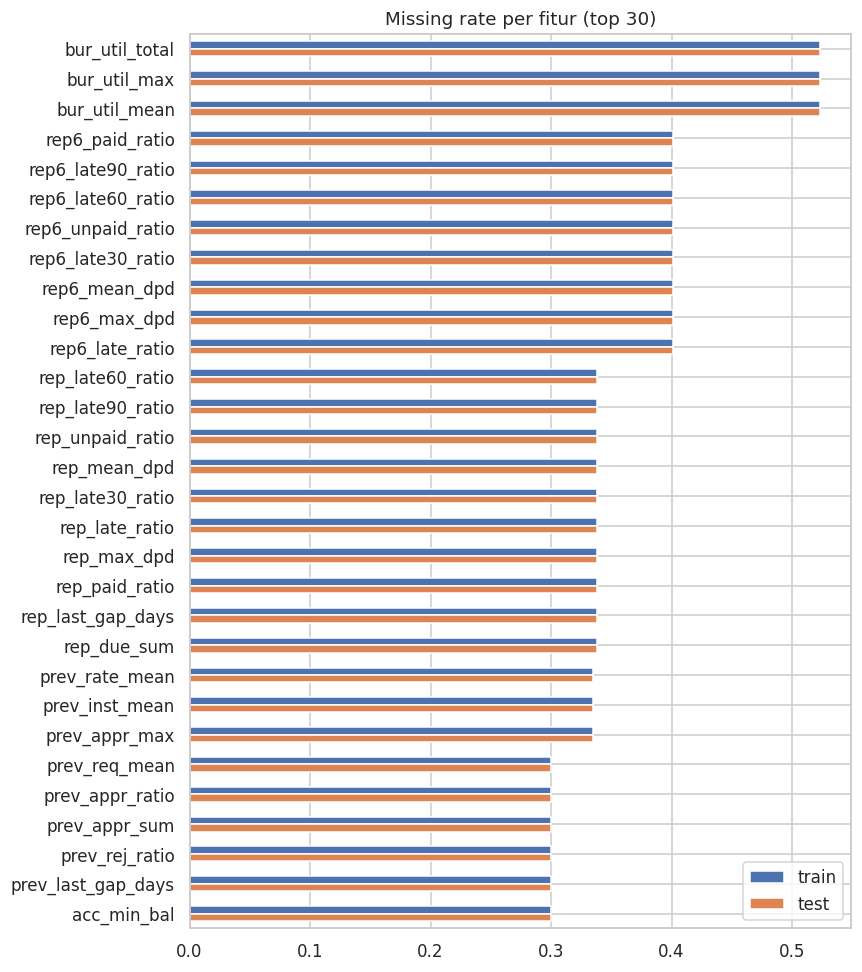

In [30]:
# [EDA] Plot missing rate per fitur
miss = pd.DataFrame({'train': Xtr[EDA_FEATS].isna().mean(), 'test': Xte[EDA_FEATS].isna().mean()})
miss = miss[(miss > 0).any(axis=1)].sort_values('train', ascending=False).head(30)
if len(miss):
    miss.plot.barh(figsize=(8, max(3, 0.3 * len(miss))))
    plt.gca().invert_yaxis(); plt.title('Missing rate per fitur (top 30)'); plt.tight_layout(); plt.show()

In [31]:
# [EDA] Fungsi KS univariat per fitur
def uni_ks(df, y, cols):
    r = {}
    for c in cols:
        x = df[c]; a = x[y == 1].dropna(); b = x[y == 0].dropna()
        if len(a) > 20 and len(b) > 20:
            r[c] = ks_2samp(a, b).statistic
    return pd.Series(r).sort_values(ascending=False)

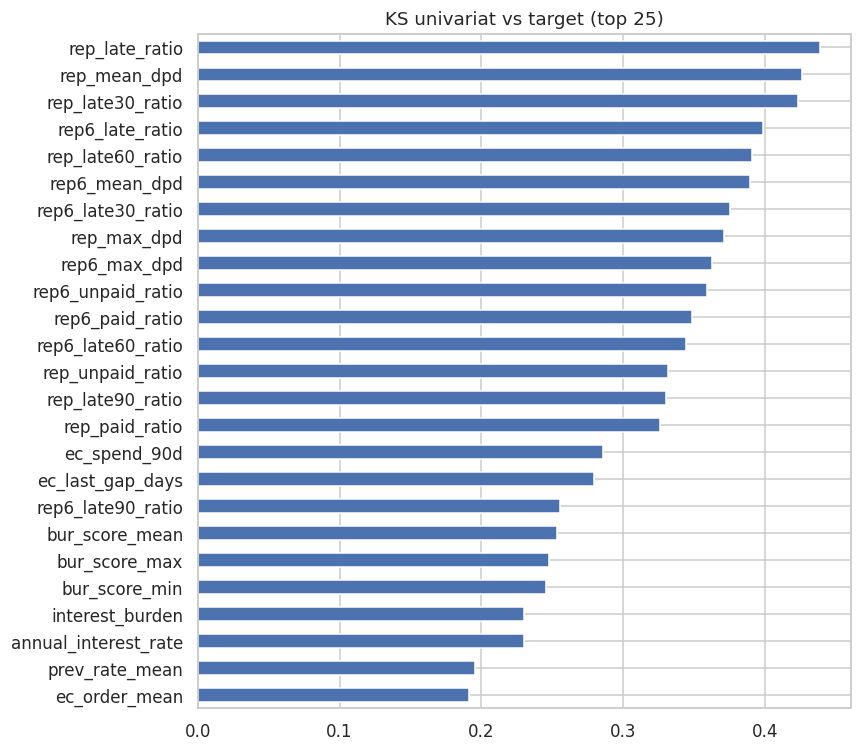

Fitur dengan KS > 0.40 (periksa kemungkinan kebocoran): ['rep_late_ratio', 'rep_mean_dpd', 'rep_late30_ratio']


In [32]:
# [EDA] KS univariat terhadap target dan deteksi fitur mencurigakan
ks_t = uni_ks(Xtr, Xtr[TARGET], num_cols)
ks_t.head(25).plot.barh(figsize=(8, 7), color='#4C72B0')
plt.gca().invert_yaxis(); plt.title('KS univariat vs target (top 25)'); plt.tight_layout(); plt.show()
sus = ks_t[ks_t > 0.40]
print('Fitur dengan KS > 0.40 (periksa kemungkinan kebocoran):', list(sus.index) if len(sus) else 'tidak ada')

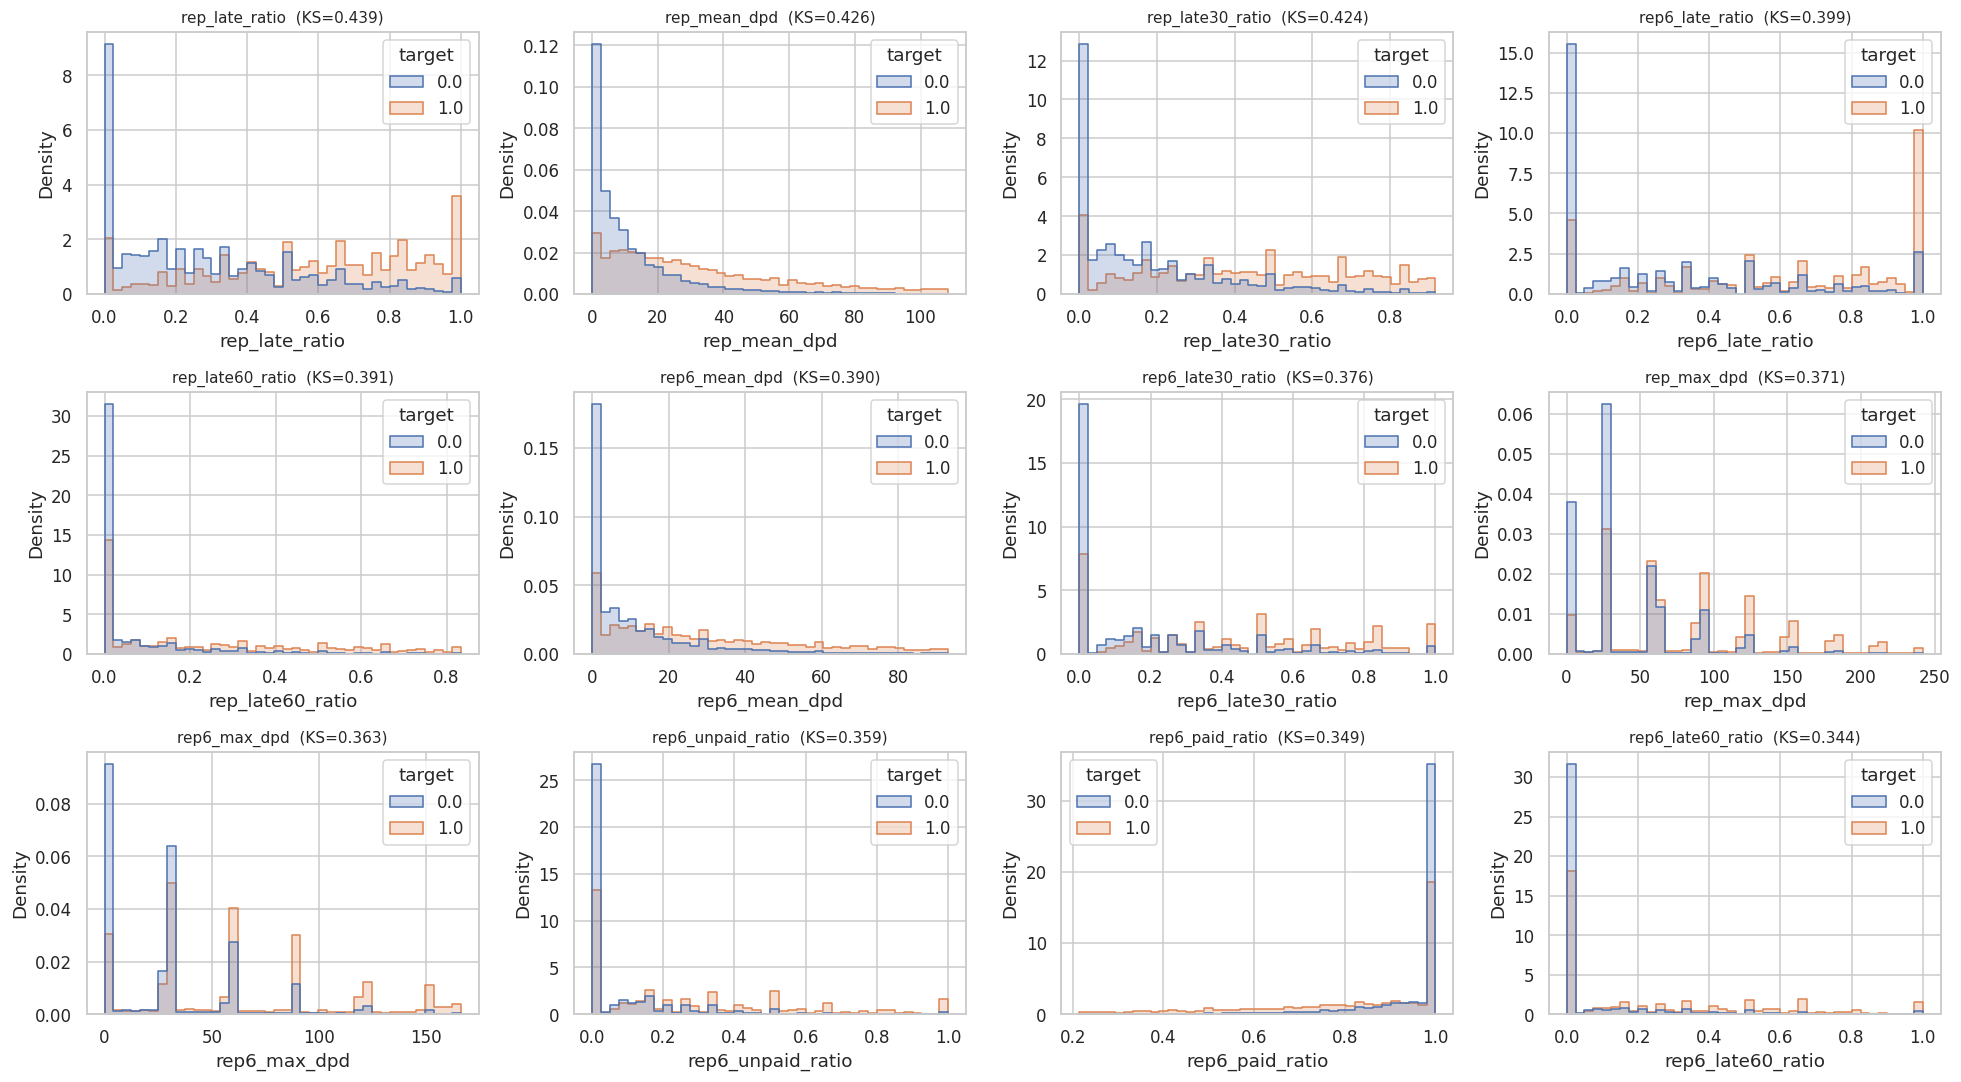

In [33]:
# [EDA] Distribusi 12 fitur teratas per kelas target
top = list(ks_t.head(12).index)
fig, axes = plt.subplots(3, 4, figsize=(18, 10))
for ax, c in zip(axes.ravel(), top):
    s = Xtr[[c, TARGET]].dropna()
    lo, hi = s[c].quantile([.01, .99])
    s = s[(s[c] >= lo) & (s[c] <= hi)]
    sns.histplot(data=s, x=c, hue=TARGET, stat='density', common_norm=False, element='step', bins=40, ax=ax)
    ax.set_title(f'{c}  (KS={ks_t[c]:.3f})', fontsize=10)
for ax in axes.ravel()[len(top):]:
    ax.axis('off')
plt.tight_layout(); plt.show()

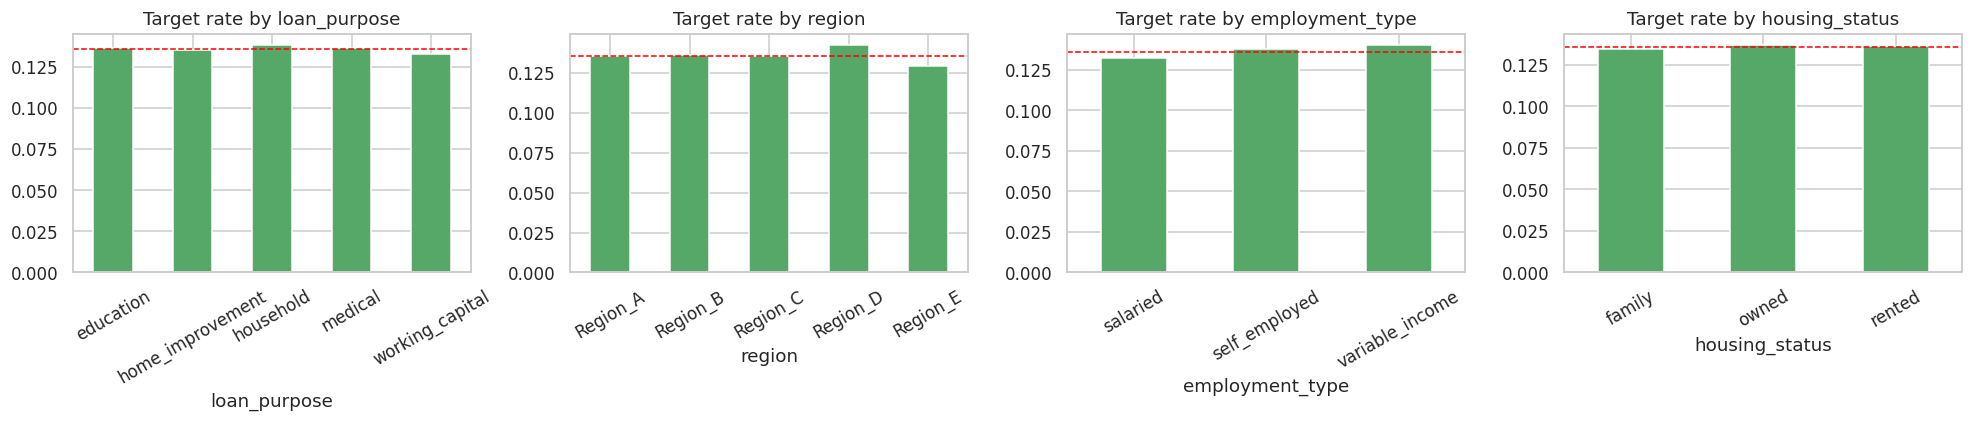

,has_prev,has_rep,has_acc,has_bur,has_ec,n
0,0,0,0,1,1,21000
1,1,0,1,1,1,2688
2,1,1,1,1,1,46312


,target_rate (tanpa riwayat),target_rate (ada riwayat)
has_prev,0.117190,0.143796
has_rep,0.121496,0.143138
has_acc,0.117190,0.143796
has_bur,NaN,0.135814
has_ec,NaN,0.135814


In [34]:
# [EDA] Target rate per kategori dan flag has_*
fig, axes = plt.subplots(1, len(CAT_COLS), figsize=(4.5 * len(CAT_COLS), 4))
for ax, c in zip(np.atleast_1d(axes), CAT_COLS):
    r = Xtr.groupby(c, observed=True)[TARGET].mean()
    r.plot.bar(ax=ax, color='#55A868'); ax.axhline(Xtr[TARGET].mean(), color='red', ls='--', lw=1)
    ax.set_title(f'Target rate by {c}'); ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

# has_* flag
display(Xtr.groupby(HAS_COLS).size().rename('n').reset_index().head(10))
display(pd.DataFrame({c: Xtr.groupby(c)[TARGET].mean() for c in HAS_COLS}).T
        .rename(columns={0: 'target_rate (tanpa riwayat)', 1: 'target_rate (ada riwayat)'}))

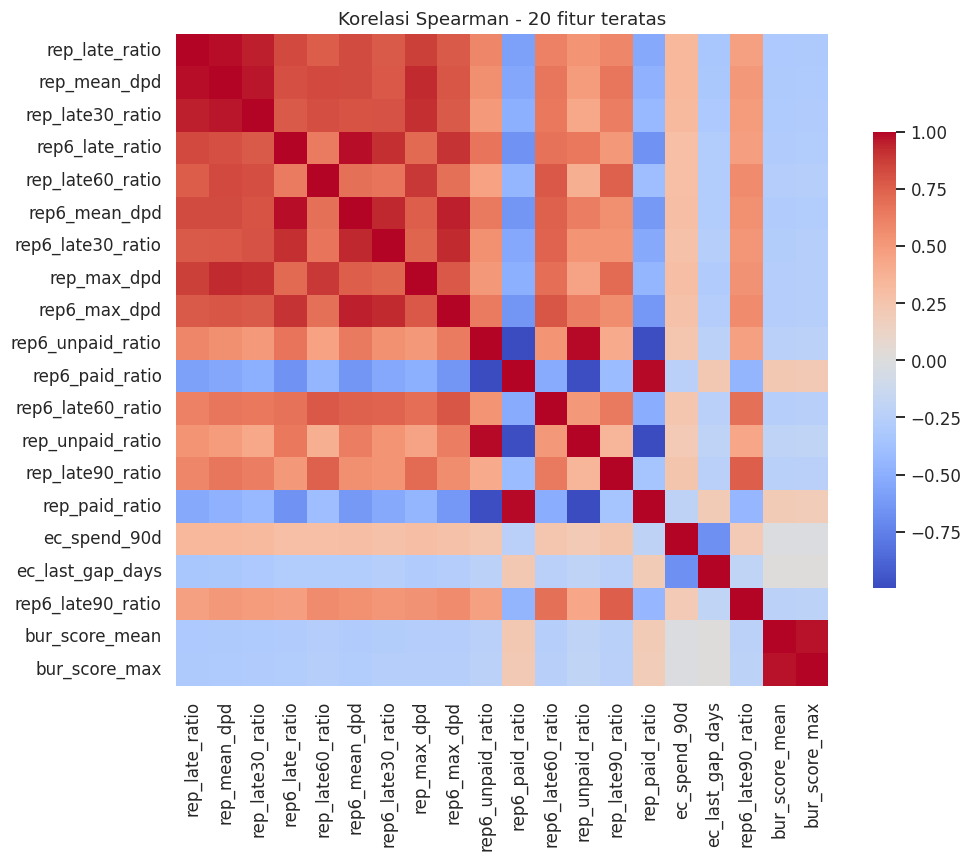

In [35]:
# [EDA] Korelasi Spearman 20 fitur teratas
t20 = list(ks_t.head(20).index)
plt.figure(figsize=(10, 8))
sns.heatmap(Xtr[t20].corr(method='spearman'), cmap='coolwarm', center=0, square=True, cbar_kws={'shrink': .7})
plt.title('Korelasi Spearman - 20 fitur teratas'); plt.tight_layout(); plt.show()

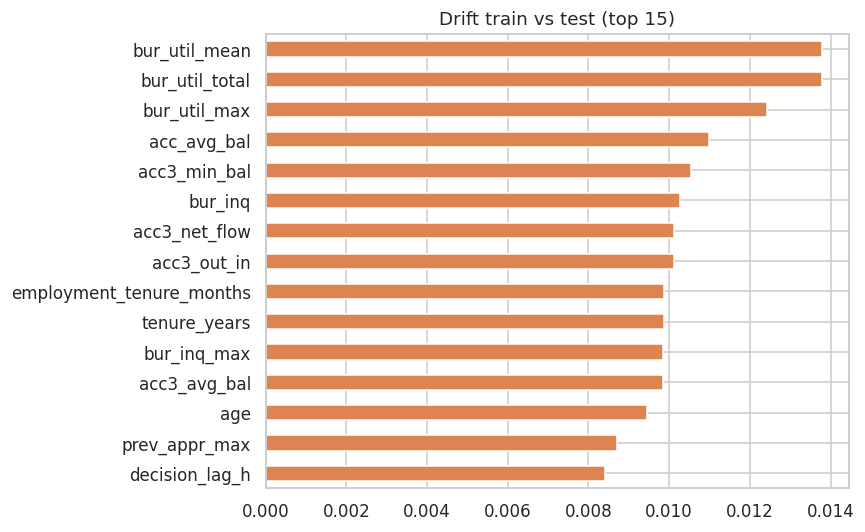

Fitur dengan drift > 0.10: tidak ada


,train,test
has_prev,0.700,0.700
has_rep,0.662,0.662
has_acc,0.700,0.700
has_bur,1.000,1.000
has_ec,1.000,1.000


In [36]:
# [EDA] Drift train vs test per fitur
drift = {}
for c in num_cols:
    a, b = Xtr[c].dropna(), Xte[c].dropna()
    if len(a) > 20 and len(b) > 20:
        drift[c] = ks_2samp(a, b).statistic
drift = pd.Series(drift).sort_values(ascending=False)
drift.head(15).plot.barh(figsize=(8, 5), color='#DD8452')
plt.gca().invert_yaxis(); plt.title('Drift train vs test (top 15)'); plt.tight_layout(); plt.show()
print('Fitur dengan drift > 0.10:', list(drift[drift > 0.10].index) or 'tidak ada')
display(pd.DataFrame({'train': Xtr[HAS_COLS].mean(),
                      'test': Xte[HAS_COLS].mean()}).round(3))

In [37]:
# [EDA] Ringkasan EDA dan rekomendasi skema validasi
print('=== RINGKASAN ===')
print(f'Target rate train : {tr.target.mean():.2%}')
print(f'Jumlah fitur      : {len(EDA_FEATS)} ({len(num_cols)} numerik, {len(CAT_COLS)} kategorikal)')
print(f'Fitur KS tertinggi: {ks_t.index[0]} ({ks_t.iloc[0]:.3f})')
ov = te.customer_id.isin(tr.customer_id).mean()
print(f'Overlap customer test-train: {ov:.1%}')
if te.decision_datetime.min() > tr.decision_datetime.quantile(0.9):
    print('Validasi: test jauh lebih baru -> pakai TIME-BASED split (latih awal, validasi akhir).')
else:
    print('Validasi: rentang waktu tumpang tindih -> pakai StratifiedGroupKFold per customer_id.')
print('Langkah berikut: jalankan bagian 6 (baseline LightGBM), ukur KS lokal, lalu submit pertama (bagian 6).')

=== RINGKASAN ===
Target rate train : 13.58%
Jumlah fitur      : 114 (110 numerik, 4 kategorikal)
Fitur KS tertinggi: rep_late_ratio (0.439)
Overlap customer test-train: 0.0%
Validasi: rentang waktu tumpang tindih -> pakai StratifiedGroupKFold per customer_id.
Langkah berikut: jalankan bagian 6 (baseline LightGBM), ukur KS lokal, lalu submit pertama (bagian 6).


In [38]:
# [Model] Fungsi pisah train/test dan buang kolom non-fitur
def split_data(FE, base_drop=BASE_DROP, extra_drop=()):
    drop = set(base_drop) | set(extra_drop)
    feats = [c for c in FE.columns if c not in drop]
    tr_, te_ = FE[FE.is_train == 1], FE[FE.is_train == 0]
    return tr_[feats], tr_['target'].astype(int), te_[feats], feats

In [39]:
# [Model] Fungsi KS (sama dengan evaluasi kompetisi)
def ks_score(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return float(ks_2samp(y_pred[y_true == 1], y_pred[y_true == 0]).statistic)

In [40]:
# [Model] Fungsi pembuat fold StratifiedKFold
def make_folds(y, n_folds=N_FOLDS, seed=SEED):
    return list(StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=seed).split(np.zeros(len(y)), y))

In [41]:
# [Model] Fungsi latih satu fold LightGBM
def fit_one_fold(X_tr, y_tr, X_va, y_va, params, seed, early_stop=EARLY_STOP):
    model = lgb.LGBMClassifier(**params, random_state=seed)
    model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], eval_metric='auc',
              callbacks=[lgb.early_stopping(early_stop, verbose=False), lgb.log_evaluation(0)])
    return model

In [42]:
# [Model] Fungsi cross-validation: OOF, prediksi test, KS per fold
def train_cv(X, y, X_test, params=LGB_PARAMS, n_folds=N_FOLDS, seed=SEED, verbose=True):
    folds = make_folds(y, n_folds, seed)
    oof, test_pred = np.zeros(len(X)), np.zeros(len(X_test))
    models, fold_ks = [], []
    for k, (i_tr, i_va) in enumerate(folds):
        t0 = time.time()
        m = fit_one_fold(X.iloc[i_tr], y.iloc[i_tr], X.iloc[i_va], y.iloc[i_va], params, seed + k)
        oof[i_va] = m.predict_proba(X.iloc[i_va])[:, 1]
        test_pred += m.predict_proba(X_test)[:, 1] / n_folds
        fold_ks.append(ks_score(y.iloc[i_va], oof[i_va])); models.append(m)
        if verbose:
            print(f'fold {k+1}/{n_folds}  KS={fold_ks[-1]:.4f}  iter={m.best_iteration_}  ({time.time()-t0:.0f}s)')
    return {'oof': oof, 'test': test_pred, 'models': models, 'fold_ks': fold_ks,
            'oof_ks': ks_score(y, oof), 'oof_auc': roc_auc_score(y, oof)}

In [43]:
# [Model] Pengelompokan fitur per sumber tabel
GROUPS = [('ec2_', 'ecommerce_v1'), ('bur2_', 'bureau_v1'), ('rep2_', 'repayment_v1'),
          ('prev2_', 'previous_v1'), ('x_', 'cross_v1'),
          ('prev_', 'previous'), ('rep6_', 'repayment_6m'), ('rep_', 'repayment'), ('acc3_', 'account_3m'),
          ('acc_', 'account'), ('bur_', 'bureau'), ('ec_', 'ecommerce'), ('has_', 'flags')]

def feat_group(name):
    for prefix, g in GROUPS:
        if name.startswith(prefix):
            return g
    return 'base'

In [44]:
# [Model] Fungsi feature importance (gain)
def feature_importance(models, feats, kind='gain'):
    imp = pd.DataFrame({f'fold{k}': m.booster_.feature_importance(kind) for k, m in enumerate(models)}, index=feats)
    imp['mean'] = imp.mean(axis=1)
    imp['share'] = imp['mean'] / imp['mean'].sum()
    imp['group'] = [feat_group(c) for c in imp.index]
    return imp.sort_values('mean', ascending=False)

In [45]:
# [Model] Fungsi plot importance
def plot_importance(imp, top=30):
    fig, ax = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={'width_ratios': [2, 1]})
    t = imp.head(top)
    sns.barplot(x='share', y=t.index, hue='group', data=t, dodge=False, ax=ax[0])
    ax[0].set_title(f'Top {top} fitur (gain share)'); ax[0].set_xlabel('share')
    g = imp.groupby('group')['share'].sum().sort_values()
    g.plot.barh(ax=ax[1], color='#4C72B0'); ax[1].set_title('Kontribusi per grup fitur (gain share)')
    plt.tight_layout(); plt.show()

In [46]:
# [Model] Fungsi plot kurva KS
def plot_ks_curve(y, p, title='OOF'):
    y, p = np.asarray(y), np.asarray(p)
    bad, good = np.sort(p[y == 1]), np.sort(p[y == 0])
    grid = np.quantile(p, np.linspace(0, 1, 1001))
    f1 = np.searchsorted(bad, grid, side='right') / len(bad)
    f0 = np.searchsorted(good, grid, side='right') / len(good)
    i = np.abs(f1 - f0).argmax()
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(grid, f1, label='default (1)', color='#C44E52'); ax[0].plot(grid, f0, label='lancar (0)', color='#4C72B0')
    ax[0].vlines(grid[i], f0[i], f1[i], color='k', ls='--', label=f'KS={abs(f1[i]-f0[i]):.4f}')
    ax[0].set_title(f'ECDF skor - {title}'); ax[0].legend()
    sns.histplot(x=p, hue=y, bins=50, stat='density', common_norm=False, element='step', ax=ax[1])
    ax[1].set_title('Distribusi skor per kelas')
    plt.tight_layout(); plt.show()

In [47]:
# [Model] Fungsi validasi format submission
def validate_submission(sub, sample):
    assert list(sub.columns) == ['application_id', 'default_probability'], 'kolom salah'
    assert len(sub) == len(sample), f'jumlah baris {len(sub)} != {len(sample)}'
    assert sub.application_id.is_unique, 'application_id duplikat'
    assert set(sub.application_id) == set(sample.application_id), 'ID tidak cocok dengan sample_submission'
    p = sub.default_probability.to_numpy()
    assert np.isfinite(p).all(), 'ada NaN/inf'
    assert ((p >= 0) & (p <= 1)).all(), 'nilai di luar 0-1'
    return True

In [48]:
# [Model] Fungsi buat file submission
def make_submission(test_index, pred, sample, path):
    sub = pd.DataFrame({'application_id': test_index, 'default_probability': np.clip(pred, 0, 1)})
    sub = sample[['application_id']].merge(sub, on='application_id', how='left')   # ikut urutan sample
    validate_submission(sub, sample)
    sub.to_csv(path, index=False)
    return sub

In [49]:
# [Model] Siapkan X, y, X_test (fitur v1 atau v0) dan cek ID test
FE_MODEL = FE1 if USE_V1 else FE
drop_extra = list(EXTRA_DROP)
if USE_V1:
    drop_extra += [c for c in FE_MODEL.columns if feat_group(c) in NOISE_GROUPS] + NOISE_COLS
    drop_extra += [c for c in FE_MODEL.columns if c.startswith(('ec2_', 'bur2_', 'rep2_', 'prev2_', 'x_')) and not c.startswith(tuple(V1_USE))]
X, y, X_test, FEATS = split_data(FE_MODEL, extra_drop=drop_extra)
print(f'train: {X.shape}  test: {X_test.shape}  target rate: {y.mean():.2%}  fitur: {len(FEATS)}  (v1 aktif: {USE_V1})')
assert set(X_test.index) == set(SUB.application_id), 'ID test di FE tidak cocok dengan sample_submission'
print('ID test cocok dengan sample_submission')

train: (70000, 215)  test: (30000, 215)  target rate: 13.58%  fitur: 215  (v1 aktif: True)
ID test cocok dengan sample_submission


In [50]:
# [Model] Jalankan cross-validation
cv = train_cv(X, y, X_test)
print(f"\nOOF KS = {cv['oof_ks']:.4f} | OOF AUC = {cv['oof_auc']:.4f} | fold KS = {np.mean(cv['fold_ks']):.4f} +/- {np.std(cv['fold_ks']):.4f}")

fold 1/5  KS=0.5048  iter=549  (31s)
fold 2/5  KS=0.5127  iter=582  (32s)
fold 3/5  KS=0.5188  iter=529  (31s)
fold 4/5  KS=0.5147  iter=274  (21s)
fold 5/5  KS=0.4824  iter=374  (25s)

OOF KS = 0.5049 | OOF AUC = 0.8334 | fold KS = 0.5067 +/- 0.0130


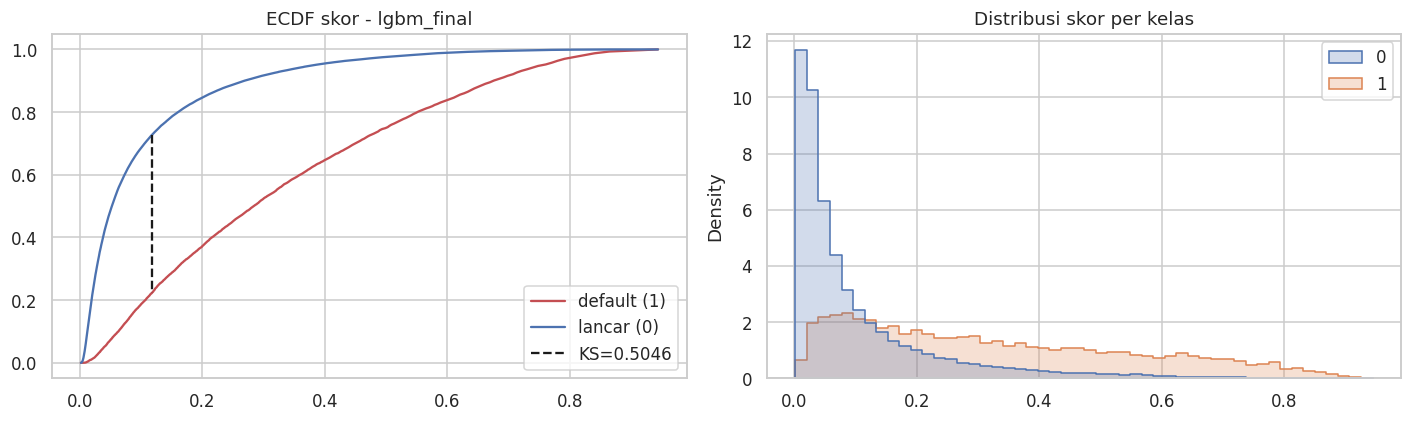

In [51]:
# [Model] Kurva KS dari prediksi OOF
plot_ks_curve(y, cv['oof'], title=EXP_NAME)

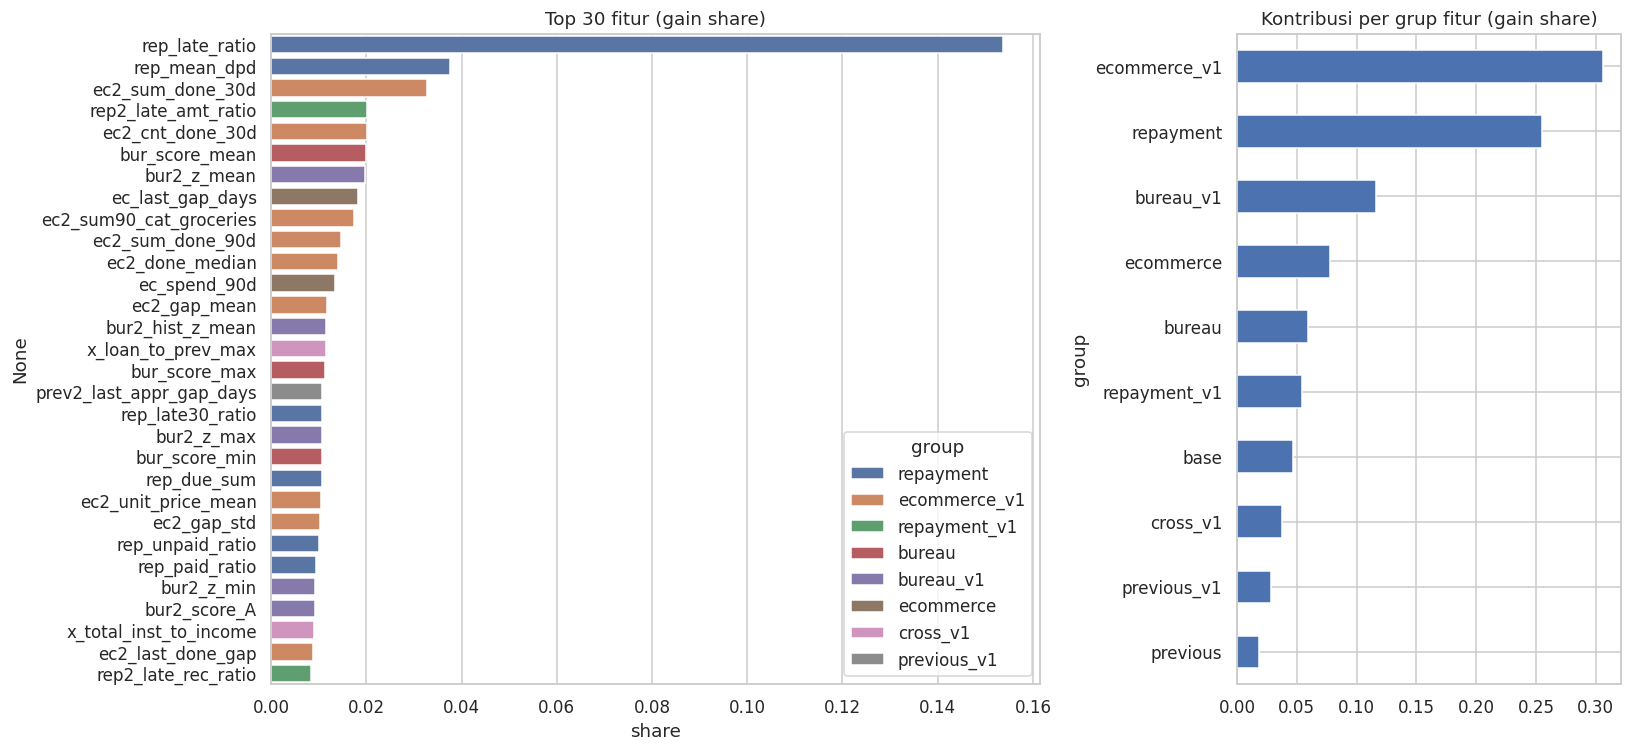

,mean,share,group
rep_late_ratio,42332.5116,0.1538,repayment
rep_mean_dpd,10340.5694,0.0376,repayment
ec2_sum_done_30d,9007.1796,0.0327,ecommerce_v1
rep2_late_amt_ratio,5560.9440,0.0202,repayment_v1
ec2_cnt_done_30d,5530.7303,0.0201,ecommerce_v1
bur_score_mean,5452.4309,0.0198,bureau
bur2_z_mean,5405.5199,0.0196,bureau_v1
ec_last_gap_days,5012.3442,0.0182,ecommerce
ec2_sum90_cat_groceries,4759.0513,0.0173,ecommerce_v1
ec2_sum_done_90d,4049.9199,0.0147,ecommerce_v1


Fitur dengan importance 0 (0): []


In [52]:
# [Model] Feature importance dan fitur dengan importance nol
imp = feature_importance(cv['models'], FEATS)
plot_importance(imp, top=30)
display(imp[['mean', 'share', 'group']].head(15).round(4))
zero = imp.index[imp['mean'] == 0].tolist()
print(f'Fitur dengan importance 0 ({len(zero)}):', zero[:20])

In [53]:
# [Model] Simpan prediksi dan buat submission.csv
tag = f'{EXP_NAME}_ks{cv["oof_ks"]:.4f}'
np.save(f'{ART_DIR}/oof_{EXP_NAME}.npy', cv['oof'])                                   # untuk ensemble nanti
pd.Series(cv['test'], index=X_test.index).to_frame('pred').to_parquet(f'{ART_DIR}/test_{EXP_NAME}.parquet')
sub_path = f'{SUB_DIR}/sub_{tag}.csv'
sub = make_submission(X_test.index, cv['test'], SUB, sub_path)
sub.to_csv('submission.csv', index=False)
print('Submission disimpan:', sub_path, sub.shape)
display(sub.head())

Submission disimpan: submissions/sub_lgbm_final_ks0.5049.csv (30000, 2)


,application_id,default_probability
0,A_a4f0104b642c9af0,0.011958
1,A_08d66c9e92ab0b7d,0.097848
2,A_9a520f63bdee8684,0.412452
3,A_7ccd9c4aa0f036b1,0.007389
4,A_559cc08a9c7fa719,0.017763


In [54]:
# [Audit] Siapkan cutoff, fitur train/test, dan daftar fitur tanpa kolom konstan
prev, rep = T['previous_applications'], T['repayment_history']
bur, eco = T['bureau_observations'], T['ecommerce_transactions']
CUT = ALL[['application_id', 'customer_id', 'decision_datetime', 'is_train']] \
        .rename(columns={'decision_datetime': 'cutoff'})
TRN, TST = FE[FE.is_train == 1], FE[FE.is_train == 0]
AUD_FEATS = [c for c in FE.columns if c not in BASE_DROP]
CONST = [c for c in AUD_FEATS if TRN[c].nunique(dropna=False) <= 1]
AUD_FEATS = [c for c in AUD_FEATS if c not in CONST]
print(f'aplikasi: {len(CUT)} | fitur audit: {len(AUD_FEATS)} | kolom konstan dibuang: {CONST}')

aplikasi: 100000 | fitur audit: 111 | kolom konstan dibuang: ['term_months', 'has_bur', 'has_ec']


In [55]:
# [Audit] Pencatat hasil pengecekan (LOLOS / PERIKSA)
FINDINGS = []
def note(part, check, ok, detail=''):
    FINDINGS.append((part, check, 'LOLOS' if ok else 'PERIKSA', detail))
    print(('[LOLOS]   ' if ok else '[PERIKSA] ') + check + (f'  -> {detail}' if detail else ''))

In [56]:
# [Audit] CV cepat dengan fold dan parameter yang sama dengan model utama
def quick_cv(X, y_, n_folds=N_FOLDS, seed=SEED):
    oof, fold_ks = np.zeros(len(X)), []
    for k, (i, j) in enumerate(make_folds(y_, n_folds, seed)):
        m = fit_one_fold(X.iloc[i], y_.iloc[i], X.iloc[j], y_.iloc[j], LGB_PARAMS, seed + k)
        oof[j] = m.predict_proba(X.iloc[j])[:, 1]
        fold_ks.append(ks_score(y_.iloc[j], oof[j]))
    return {'oof_ks': ks_score(y_, oof), 'fold_mean': float(np.mean(fold_ks)), 'fold_std': float(np.std(fold_ks))}

In [57]:
# [Audit repayment] Pasangkan tiap cicilan dengan cutoff dan hitung hari berjalan
R = rep.merge(CUT[['customer_id', 'application_id', 'cutoff']], on='customer_id', how='inner')
R['elapsed'] = (R['cutoff'].dt.normalize() - R['due_date'].dt.normalize()).dt.days
print('baris cicilan x aplikasi:', len(R))

baris cicilan x aplikasi: 1361341


In [58]:
# [Audit repayment] Pelanggaran dasar (harus 0): baris setelah cutoff, DPD > hari berjalan, dst.
has_pay = R.last_payment_datetime.notna()
checks = {
    'due_date >= cutoff': (R.due_date >= R.cutoff).sum(),
    'last_payment_datetime > cutoff': (R.last_payment_datetime > R.cutoff).sum(),
    'days_past_due > hari berjalan (+1)': (R.days_past_due > R.elapsed + 1).sum(),
    'max_days_past_due > hari berjalan (+1)': (R.max_days_past_due > R.elapsed + 1).sum(),
    'days_past_due > max_days_past_due': (R.days_past_due > R.max_days_past_due).sum(),
    'amount_paid > amount_due': (R.amount_paid > R.amount_due).sum(),
    'tanpa last_payment tapi amount_paid > 0': ((~has_pay) & (R.amount_paid > 0)).sum(),
    'ada last_payment tapi amount_paid == 0': (has_pay & (R.amount_paid == 0)).sum(),
}
tab = pd.DataFrame({'n': checks}); tab['%'] = (tab.n / len(R) * 100).round(4)
display(tab)
note('A', 'tidak ada due_date/last_payment setelah cutoff', checks['due_date >= cutoff'] == 0 and checks['last_payment_datetime > cutoff'] == 0)
note('A', 'DPD tidak melebihi hari berjalan sampai cutoff',
     checks['days_past_due > hari berjalan (+1)'] == 0 and checks['max_days_past_due > hari berjalan (+1)'] == 0,
     f"dpd={checks['days_past_due > hari berjalan (+1)']}, max_dpd={checks['max_days_past_due > hari berjalan (+1)']}")

,n,%
due_date >= cutoff,0,0.0
last_payment_datetime > cutoff,0,0.0
days_past_due > hari berjalan (+1),0,0.0
max_days_past_due > hari berjalan (+1),0,0.0
days_past_due > max_days_past_due,0,0.0
amount_paid > amount_due,0,0.0
tanpa last_payment tapi amount_paid > 0,0,0.0
ada last_payment tapi amount_paid == 0,0,0.0


[LOLOS]   tidak ada due_date/last_payment setelah cutoff
[LOLOS]   DPD tidak melebihi hari berjalan sampai cutoff  -> dpd=0, max_dpd=0


In [59]:
# [Audit repayment] Rekonstruksi DPD dari timestamp, bandingkan dengan kolom DPD (lunas ~1,0 dan belum lunas ~1,0 = sesuai snapshot)
unpaid = R.amount_paid < R.amount_due
late_at_pay = (R.last_payment_datetime.dt.normalize() - R.due_date.dt.normalize()).dt.days
R['dpd_rec'] = np.where(unpaid, np.clip(R.elapsed, 0, None), np.clip(late_at_pay.fillna(0), 0, None))
R['status'] = np.where(unpaid, 'belum lunas', 'lunas')

cmp_ = pd.DataFrame({
    'status': R.status,
    'days_past_due ~ rekonstruksi': (R.days_past_due - R.dpd_rec).abs() <= 1,
    'max_days_past_due ~ rekonstruksi': (R.max_days_past_due - R.dpd_rec).abs() <= 1,
    'days_past_due == 0': R.days_past_due == 0,
})
res = cmp_.groupby('status').mean().round(4); res['n'] = cmp_.groupby('status').size()
display(res)

,days_past_due ~ rekonstruksi,max_days_past_due ~ rekonstruksi,days_past_due == 0,n
status,,,,
belum lunas,1.0000,1.0,0.0144,58783
lunas,0.6911,1.0,1.0000,1302558


In [60]:
# [Audit repayment] Contoh baris yang tidak cocok
bad = R[(R.days_past_due - R.dpd_rec).abs() > 1]
print('baris tidak cocok:', len(bad), f'({len(bad)/len(R):.2%})')
display(bad[['due_date', 'last_payment_datetime', 'cutoff', 'amount_due', 'amount_paid',
             'days_past_due', 'max_days_past_due', 'elapsed', 'dpd_rec']].head(10))

baris tidak cocok: 402397 (29.56%)


,due_date,last_payment_datetime,cutoff,amount_due,amount_paid,days_past_due,max_days_past_due,elapsed,dpd_rec
13,2024-02-20 12:54:00,2024-03-20 12:54:00,2025-06-12 18:54:00,523565,523565,0,28,478,29.0
14,2024-03-20 12:54:00,2024-04-20 12:54:00,2025-06-12 18:54:00,523565,523565,0,30,449,31.0
38,2024-09-11 01:36:00,2024-10-11 01:36:00,2025-11-27 08:36:00,2123103,2123103,0,29,442,30.0
39,2024-10-11 01:36:00,2024-11-11 01:36:00,2025-11-27 08:36:00,2123103,2123103,0,30,412,31.0
40,2024-11-11 01:36:00,2025-02-11 01:36:00,2025-11-27 08:36:00,2123103,2123103,0,91,381,92.0
41,2024-12-11 01:36:00,2025-05-11 01:36:00,2025-11-27 08:36:00,2123103,2123103,0,150,351,151.0
42,2025-01-11 01:36:00,2025-05-11 01:36:00,2025-11-27 08:36:00,2123103,2123103,0,119,320,120.0
43,2025-02-11 01:36:00,2025-06-11 01:36:00,2025-11-27 08:36:00,2123103,2123103,0,119,289,120.0
44,2025-03-11 01:36:00,2025-08-11 01:36:00,2025-11-27 08:36:00,2123091,2123091,0,152,261,153.0
47,2023-10-16 16:45:00,2023-11-16 16:45:00,2025-08-22 19:45:00,1937287,1937287,0,30,676,31.0


In [61]:
# [Audit repayment] Hubungan loan_id dengan previous_applications
pl = prev.loc[prev.loan_id.notna(), ['customer_id', 'loan_id', 'decision_datetime']] \
         .rename(columns={'decision_datetime': 'loan_decision'}).drop_duplicates(['customer_id', 'loan_id'])
M = R[['customer_id', 'loan_id', 'due_date', 'cutoff']].merge(pl, on=['customer_id', 'loan_id'], how='left')
found = M.loan_decision.notna().mean()
after_cut = (M.loan_decision >= M.cutoff).mean()
due_before_loan = (M.due_date < M.loan_decision).mean()
print(f'loan_id cicilan ditemukan di previous_applications : {found:.2%}')
print(f'pinjaman lama diputuskan setelah cutoff            : {after_cut:.4%}')
print(f'cicilan jatuh tempo sebelum pinjamannya diputuskan : {due_before_loan:.4%}')
note('A', 'pinjaman lama pada riwayat cicilan tidak diputuskan setelah cutoff', after_cut == 0 or np.isnan(after_cut), f'{after_cut:.4%}')

loan_id cicilan ditemukan di previous_applications : 100.00%
pinjaman lama diputuskan setelah cutoff            : 0.0000%
cicilan jatuh tempo sebelum pinjamannya diputuskan : 0.0000%
[LOLOS]   pinjaman lama pada riwayat cicilan tidak diputuskan setelah cutoff  -> 0.0000%


In [62]:
# [Audit repayment] Drift fitur repayment antara train dan test
rep_cols = [c for c in AUD_FEATS if c.startswith(('rep_', 'rep6_'))]
TST = FE[FE.is_train == 0]
drift = pd.Series({c: ks_2samp(TRN[c].dropna(), TST[c].dropna()).statistic for c in rep_cols}).sort_values(ascending=False)
display(drift.head(8).round(4).to_frame('KS train vs test'))
note('A', 'fitur repayment tidak berbeda distribusi antara train dan test', drift.max() < 0.05, f'KS maks = {drift.max():.4f}')

,KS train vs test
rep_late30_ratio,0.0084
rep_mean_dpd,0.0070
rep_late_ratio,0.0063
rep6_late30_ratio,0.0063
rep6_late_ratio,0.0058
rep_due_sum,0.0050
rep_last_gap_days,0.0044
rep_late90_ratio,0.0042


[LOLOS]   fitur repayment tidak berbeda distribusi antara train dan test  -> KS maks = 0.0084


In [63]:
# [Audit repayment] Fitur repayment versi aman (hanya dari timestamp)
def f_repay_safe(A, R_):
    m = join_before(A, R_, 'due_date')
    paid = m.last_payment_datetime.notna()
    late_pay = (m.last_payment_datetime.dt.normalize() - m.due_date.dt.normalize()).dt.days
    elapsed = (m.cutoff.dt.normalize() - m.due_date.dt.normalize()).dt.days
    m = m.assign(late_days=np.clip(np.where(paid, late_pay, elapsed), 0, None),
                 unpaid=(~paid).astype(int), days_since_due=elapsed)
    m = m.assign(late=(m.late_days > 0).astype(int), late30=(m.late_days >= 30).astype(int),
                 late60=(m.late_days >= 60).astype(int), late90=(m.late_days >= 90).astype(int))
    def block(d, p):
        return d.groupby('application_id').agg(**{
            f'{p}_cnt_inst': ('installment_id', 'size'), f'{p}_max_late': ('late_days', 'max'),
            f'{p}_mean_late': ('late_days', 'mean'), f'{p}_late_ratio': ('late', 'mean'),
            f'{p}_late30_ratio': ('late30', 'mean'), f'{p}_late60_ratio': ('late60', 'mean'),
            f'{p}_late90_ratio': ('late90', 'mean'), f'{p}_unpaid_ratio': ('unpaid', 'mean')})
    out = block(m, 'rsafe').join(block(m[m.days_since_due <= 180], 'rsafe6'))
    out['rsafe_cnt_loans'] = m.groupby('application_id')['loan_id'].nunique()
    out['rsafe_last_gap_days'] = m.groupby('application_id')['days_since_due'].min()
    return out

In [64]:
# [Audit repayment] Bangun fitur aman untuk semua aplikasi
SAFE = f_repay_safe(ALL, rep)
cnt = [c for c in SAFE.columns if '_cnt' in c]
SAFE[cnt] = SAFE[cnt].fillna(0)
print('fitur aman:', SAFE.shape)

fitur aman: (66157, 18)


In [65]:
# [Audit repayment] Fungsi susun X per varian fitur dan jalankan CV
def make_X(drop_prefix=(), drop_cols=(), add=None):
    cols = [c for c in AUD_FEATS if not c.startswith(tuple(drop_prefix)) and c not in set(drop_cols)] if drop_prefix \
           else [c for c in AUD_FEATS if c not in set(drop_cols)]
    X = TRN[cols]
    if add is not None:
        X = X.join(add, how='left')
    return X

RES = []
def run_variant(name, **kw):
    r = quick_cv(make_X(**kw), y); r['varian'] = name; r['n_fitur'] = make_X(**kw).shape[1]
    RES.append(r); return r

In [66]:
# [Audit repayment] Bandingkan KS: fitur asli vs aman vs tanpa repayment (selisih kecil = DPD bersih)
if RUN_AUDIT:
    run_variant('asli (rep_* + rep6_*)')
    run_variant('aman (hanya timestamp)', drop_prefix=('rep_', 'rep6_'), add=SAFE)
    run_variant('tanpa repayment sama sekali', drop_prefix=('rep_', 'rep6_'))
    res_rep = pd.DataFrame(RES)[['varian', 'n_fitur', 'oof_ks', 'fold_mean', 'fold_std']].round(4)
    display(res_rep)
    d = res_rep.oof_ks[0] - res_rep.oof_ks[1]
    note('A', 'KS fitur repayment aman ~ KS asli', abs(d) < 0.01, f'selisih asli - aman = {d:+.4f}')

,varian,n_fitur,oof_ks,fold_mean,fold_std
0,asli (rep_* + rep6_*),111,0.4950,0.4976,0.0140
1,aman (hanya timestamp),108,0.4939,0.4963,0.0109
2,tanpa repayment sama sekali,90,0.4463,0.4483,0.0151


[LOLOS]   KS fitur repayment aman ~ KS asli  -> selisih asli - aman = +0.0011


In [67]:
# [Audit profil] Keunikan dan kewajaran nilai profil
pr_num = ['age', 'employment_tenure_months', 'declared_monthly_income', 'dependents']
display(prof[pr_num].describe().round(1).T)
viol = {
    'customer_id duplikat': int(prof.customer_id.duplicated().sum()),
    'masa kerja > (usia-15) tahun': int((prof.employment_tenure_months > (prof.age - 15) * 12).sum()),
    'penghasilan <= 0': int((prof.declared_monthly_income <= 0).sum()),
    'usia di luar 18-80': int(((prof.age < 18) | (prof.age > 80)).sum()),
}
print(viol)
note('B', 'profil unik per customer dan nilai wajar', sum(viol.values()) == 0, str(viol))

,count,mean,std,min,25%,50%,75%,max
age,100000.0,41.5,11.0,23.0,32.0,42.0,51.0,60.0
employment_tenure_months,100000.0,51.6,33.8,3.0,26.0,44.0,69.0,297.0
declared_monthly_income,100000.0,9309719.0,6168829.8,490493.0,5115223.5,7775115.0,11745819.5,91954431.0
dependents,100000.0,1.6,1.2,0.0,1.0,2.0,2.0,4.0


{'customer_id duplikat': 0, 'masa kerja > (usia-15) tahun': 0, 'penghasilan <= 0': 0, 'usia di luar 18-80': 0}
[LOLOS]   profil unik per customer dan nilai wajar  -> {'customer_id duplikat': 0, 'masa kerja > (usia-15) tahun': 0, 'penghasilan <= 0': 0, 'usia di luar 18-80': 0}


In [68]:
# [Audit profil] Korelasi profil dengan waktu keputusan
P = ALL[['application_id', 'customer_id', 'decision_datetime']].merge(prof, on='customer_id', how='left')
P['t'] = P.decision_datetime.astype('int64') // 10**9
rows = {c: spearmanr(P['t'], P[c], nan_policy='omit')[0] for c in pr_num}
sp = pd.Series(rows).round(4).to_frame('Spearman dengan waktu keputusan')
display(sp)
mon_tab = P.groupby(P.decision_datetime.dt.to_period('M'))[pr_num].mean().round(1)
display(mon_tab)
note('B', 'profil tidak berkorelasi dengan waktu keputusan', sp.abs().max().iloc[0] < 0.03,
     f'|rho| maks = {sp.abs().max().iloc[0]:.4f}')

,Spearman dengan waktu keputusan
age,0.0011
employment_tenure_months,0.0032
declared_monthly_income,-0.0066
dependents,-0.0003


,age,employment_tenure_months,declared_monthly_income,dependents
decision_datetime,,,,
2025-01,41.5,51.1,9343337.4,1.7
2025-02,41.5,52.0,9471389.8,1.7
2025-03,41.4,51.1,9274692.6,1.6
2025-04,41.5,52.2,9350895.7,1.6
2025-05,41.5,52.0,9340641.8,1.7
2025-06,41.6,51.4,9237227.4,1.7
2025-07,41.7,51.2,9376946.3,1.6
2025-08,41.4,51.3,9235317.8,1.7
2025-09,41.5,51.3,9332598.5,1.7


[LOLOS]   profil tidak berkorelasi dengan waktu keputusan  -> |rho| maks = 0.0066


In [69]:
# [Audit profil] KS vs target dan drift train/test kolom profil
prof_cols = [c for c in AUD_FEATS if c in ['age', 'region', 'employment_type', 'employment_tenure_months',
             'declared_monthly_income', 'dependents', 'housing_status', 'inst_to_income',
             'loan_to_annual_income', 'income_per_dependent', 'tenure_years']]
num_p = [c for c in prof_cols if str(FE[c].dtype) != 'category']
out = pd.DataFrame({'KS vs target': {c: ks_2samp(TRN.loc[y == 1, c].dropna(), TRN.loc[y == 0, c].dropna()).statistic for c in num_p},
                    'KS train vs test': {c: ks_2samp(TRN[c].dropna(), TST[c].dropna()).statistic for c in num_p}}).round(4)
display(out.sort_values('KS vs target', ascending=False))
note('B', 'profil tidak berbeda distribusi antara train dan test', out['KS train vs test'].max() < 0.05,
     f"maks = {out['KS train vs test'].max():.4f}")

,KS vs target,KS train vs test
inst_to_income,0.0778,0.0058
loan_to_annual_income,0.0684,0.0058
income_per_dependent,0.0288,0.0059
declared_monthly_income,0.0236,0.0057
dependents,0.0134,0.0041
employment_tenure_months,0.0124,0.0099
tenure_years,0.0124,0.0099
age,0.0106,0.0095


[LOLOS]   profil tidak berbeda distribusi antara train dan test  -> maks = 0.0099


In [70]:
# [Audit profil] Ablasi: KS tanpa kolom profil
if RUN_AUDIT:
    run_variant('tanpa kolom profil', drop_cols=prof_cols)
    res_all = pd.DataFrame(RES)[['varian', 'n_fitur', 'oof_ks', 'fold_mean', 'fold_std']].round(4)
    display(res_all)
    d = res_all.oof_ks[0] - res_all.oof_ks.iloc[-1]
    note('B', 'kontribusi profil terhadap KS wajar (tidak mendominasi)', d < 0.03, f'KS turun {d:.4f} jika profil dibuang')

,varian,n_fitur,oof_ks,fold_mean,fold_std
0,asli (rep_* + rep6_*),111,0.4950,0.4976,0.0140
1,aman (hanya timestamp),108,0.4939,0.4963,0.0109
2,tanpa repayment sama sekali,90,0.4463,0.4483,0.0151
3,tanpa kolom profil,100,0.4966,0.4986,0.0134


[LOLOS]   kontribusi profil terhadap KS wajar (tidak mendominasi)  -> KS turun -0.0016 jika profil dibuang


In [71]:
# [Audit join] Integritas FE: satu baris per aplikasi, tanpa target/ID di fitur
note('C', 'satu baris per application_id di FE', FE.index.is_unique and len(FE) == len(ALL), f'FE={len(FE)}, ALL={len(ALL)}')
leak_names = [c for c in AUD_FEATS if c in ('target', 'application_id', 'customer_id') or c.endswith('_id')]
note('C', 'tidak ada kolom target/ID di fitur', len(leak_names) == 0, str(leak_names))
note('C', 'kolom fitur train == test', list(FE[FE.is_train == 0][AUD_FEATS].columns) == list(TRN[AUD_FEATS].columns))

[LOLOS]   satu baris per application_id di FE  -> FE=100000, ALL=100000
[LOLOS]   tidak ada kolom target/ID di fitur  -> []
[LOLOS]   kolom fitur train == test


In [72]:
# [Audit join] previous_applications: overlap ID dan baris setelah cutoff
ov = len(set(prev.application_id) & set(ALL.application_id))
pj = prev.merge(CUT[['customer_id', 'cutoff']], on='customer_id')
after = (pj.decision_datetime >= pj.cutoff).mean()
orig_no_id = ((prev.decision == 'approved') & prev.loan_id.isna()).sum()
print(f'ID pengajuan lama yang sama dengan pengajuan yang dinilai: {ov}')
print(f'baris riwayat dengan keputusan >= cutoff: {after:.4%}')
print(f'approved tanpa loan_id: {orig_no_id}')
note('C', 'pengajuan yang dinilai tidak ikut sebagai riwayat', ov == 0, f'overlap ID = {ov}')

ID pengajuan lama yang sama dengan pengajuan yang dinilai: 0
baris riwayat dengan keputusan >= cutoff: 0.0000%
approved tanpa loan_id: 0
[LOLOS]   pengajuan yang dinilai tidak ikut sebagai riwayat  -> overlap ID = 0


In [73]:
# [Audit join] bureau: laporan terbit vs tersedia dan aplikasi tanpa laporan
b = bur.merge(CUT[['application_id', 'cutoff']], on='application_id', how='inner')
rep_ok_avail_late = ((b.report_datetime <= b.cutoff) & (b.available_datetime > b.cutoff)).sum()
n_per = b.groupby(['application_id', 'bureau_provider']).size()
avail = b[b.available_datetime <= b.cutoff]
no_report = len(CUT) - avail.application_id.nunique()
print(f'laporan terbit sebelum cutoff tapi baru tersedia sesudahnya: {rep_ok_avail_late}')
print(f'(aplikasi, provider) dengan >1 laporan: {(n_per > 1).sum()}')
print(f'aplikasi tanpa laporan tersedia: {no_report} ({no_report/len(CUT):.2%})')
print('Baris yang terbit sebelum cutoff tetapi baru tersedia sesudahnya sudah dikeluarkan lewat filter available_datetime.')

laporan terbit sebelum cutoff tapi baru tersedia sesudahnya: 0
(aplikasi, provider) dengan >1 laporan: 0
aplikasi tanpa laporan tersedia: 0 (0.00%)
Baris yang terbit sebelum cutoff tetapi baru tersedia sesudahnya sudah dikeluarkan lewat filter available_datetime.


In [74]:
# [Audit join] ecommerce: konsistensi atribut per order
g = eco.groupby('order_id').agg(n_total=('order_total', 'nunique'), n_status=('order_status', 'nunique'),
                                n_pay=('payment_method', 'nunique'), n_time=('transaction_datetime', 'nunique'))
bad_orders = (g > 1).any(axis=1).sum()
print(f'order dengan atribut tidak konsisten antar item: {bad_orders} dari {len(g)}')
note('C', 'ecommerce: atribut order konsisten antar item', bad_orders == 0, f'{bad_orders} order bermasalah')

order dengan atribut tidak konsisten antar item: 0 dari 2986855
[LOLOS]   ecommerce: atribut order konsisten antar item  -> 0 order bermasalah


In [75]:
# [Audit join] account: hanya bulan lengkap sebelum cutoff
a = T['account_behavior'].assign(month_end=lambda d: d['month'] + pd.offsets.MonthBegin(1))
a = join_before(ALL, a, 'month_end', le=True)
viol_m = (a.month_end > a.cutoff).sum()
months_per = a.groupby('application_id').size()
print('pelanggaran batas bulan:', viol_m)
print('bulan lengkap per aplikasi:', months_per.describe().round(1).to_dict())
print(f'aplikasi tanpa riwayat akun: {len(CUT) - months_per.shape[0]}')
note('C', 'account: hanya bulan lengkap sebelum cutoff', viol_m == 0, f'pelanggaran = {viol_m}')

pelanggaran batas bulan: 0
bulan lengkap per aplikasi: {'count': 70000.0, 'mean': 15.5, 'std': 4.6, 'min': 8.0, '25%': 11.0, '50%': 15.0, '75%': 20.0, 'max': 23.0}
aplikasi tanpa riwayat akun: 30000
[LOLOS]   account: hanya bulan lengkap sebelum cutoff  -> pelanggaran = 0


In [76]:
# [Audit validasi] KS kita vs fungsi evaluasi kompetisi pada OOF
def comp_score(solution, submission, row_id_column_name):
    target_col = 'default_probability'
    sol = solution.sort_values(by=row_id_column_name).reset_index(drop=True)
    sub = submission.sort_values(by=row_id_column_name).reset_index(drop=True)
    y_true, y_pred = sol[target_col].to_numpy(), sub[target_col].to_numpy()
    return float(ks_2samp(y_pred[y_true == 1], y_pred[y_true == 0]).statistic)

a1 = comp_score(pd.DataFrame({'application_id': TRN.index, 'default_probability': y.values}),
                pd.DataFrame({'application_id': TRN.index, 'default_probability': cv['oof']}), 'application_id')
a2 = ks_score(y, cv['oof'])
print('KS kompetisi:', round(a1, 6), '| KS kita:', round(a2, 6))
note('D', 'ks_score identik dengan fungsi evaluasi kompetisi', abs(a1 - a2) < 1e-9, f'{a1:.4f} vs {a2:.4f}')

KS kompetisi: 0.504946 | KS kita: 0.504946
[LOLOS]   ks_score identik dengan fungsi evaluasi kompetisi  -> 0.5049 vs 0.5049


In [77]:
# [Audit validasi] Validasi berbasis waktu vs acak
if RUN_AUDIT:
    Xd = TRN[AUD_FEATS]
    cut_t = TRN.decision_datetime.quantile(0.7)
    itr = (TRN.decision_datetime < cut_t).to_numpy()
    P_ = {**LGB_PARAMS, 'n_estimators': 400}
    m_t = lgb.LGBMClassifier(**P_, random_state=SEED).fit(Xd[itr], y[itr])
    ks_time = ks_score(y[~itr], m_t.predict_proba(Xd[~itr])[:, 1])

    rng = np.random.default_rng(SEED)
    ir = np.zeros(len(Xd), bool); ir[rng.choice(len(Xd), itr.sum(), replace=False)] = True
    m_r = lgb.LGBMClassifier(**P_, random_state=SEED).fit(Xd[ir], y[ir])
    ks_rand = ks_score(y[~ir], m_r.predict_proba(Xd[~ir])[:, 1])
    print(f'KS validasi waktu (latih sebelum {cut_t:%Y-%m-%d}): {ks_time:.4f}')
    print(f'KS validasi acak (ukuran sama)                 : {ks_rand:.4f}')
    note('D', 'validasi berbasis waktu ~ acak (tidak ada pergeseran waktu)', abs(ks_time - ks_rand) < 0.02,
         f'waktu={ks_time:.4f}, acak={ks_rand:.4f}')

KS validasi waktu (latih sebelum 2025-09-12): 0.4883
KS validasi acak (ukuran sama)                 : 0.5015
[LOLOS]   validasi berbasis waktu ~ acak (tidak ada pergeseran waktu)  -> waktu=0.4883, acak=0.5015


In [78]:
# [Audit] Tabel ringkasan semua pengecekan
ringkasan = pd.DataFrame(FINDINGS, columns=['bagian', 'pengecekan', 'hasil', 'detail'])
display(ringkasan)
print(ringkasan.hasil.value_counts().to_dict())

,bagian,pengecekan,hasil,detail
0,A,tidak ada due_date/last_payment setelah cutoff,LOLOS,
1,A,DPD tidak melebihi hari berjalan sampai cutoff,LOLOS,"dpd=0, max_dpd=0"
2,A,pinjaman lama pada riwayat cicilan tidak diput...,LOLOS,0.0000%
3,A,fitur repayment tidak berbeda distribusi antar...,LOLOS,KS maks = 0.0084
4,A,KS fitur repayment aman ~ KS asli,LOLOS,selisih asli - aman = +0.0011
5,B,profil unik per customer dan nilai wajar,LOLOS,"{'customer_id duplikat': 0, 'masa kerja > (usi..."
6,B,profil tidak berkorelasi dengan waktu keputusan,LOLOS,|rho| maks = 0.0066
7,B,profil tidak berbeda distribusi antara train d...,LOLOS,maks = 0.0099
8,B,kontribusi profil terhadap KS wajar (tidak men...,LOLOS,KS turun -0.0016 jika profil dibuang
9,C,satu baris per application_id di FE,LOLOS,"FE=100000, ALL=100000"


{'LOLOS': 17}


In [79]:
# [Importance] Fungsi permutation importance: penurunan KS saat satu fitur diacak di data validasi
def permutation_ks(models, X, y, folds, n_repeats=1, seed=SEED):
    rng = np.random.default_rng(seed)
    rows = {c: [] for c in X.columns}
    for m, (_, j) in zip(models, folds):
        Xv, yv = X.iloc[j], y.iloc[j]
        base = ks_score(yv, m.predict_proba(Xv)[:, 1])
        for c in X.columns:
            drops = []
            for _ in range(n_repeats):
                Xp = Xv.copy()
                Xp[c] = Xp[c].sample(frac=1, random_state=int(rng.integers(1e9))).values
                drops.append(base - ks_score(yv, m.predict_proba(Xp)[:, 1]))
            rows[c].append(np.mean(drops))
    res = pd.DataFrame(rows).T
    res.columns = [f'fold{k + 1}' for k in range(res.shape[1])]
    res['mean'] = res.mean(axis=1)
    res['std'] = res.iloc[:, :-1].std(axis=1)
    return res.sort_values('mean', ascending=False)

In [80]:
# [Importance] Fungsi SHAP bawaan LightGBM: rata-rata |SHAP| dan arah pengaruh (+ naik risiko, - turun risiko)
def shap_summary(model, X_, max_rows=10000, seed=SEED):
    Xs = X_.sample(min(max_rows, len(X_)), random_state=seed)
    contrib = model.predict_proba(Xs, pred_contrib=True)[:, :-1]
    out = pd.DataFrame({'shap_abs': np.abs(contrib).mean(axis=0)}, index=Xs.columns)
    arah = {}
    for j, c in enumerate(Xs.columns):
        if str(Xs[c].dtype) == 'category':
            arah[c] = np.nan; continue
        v, s = Xs[c].to_numpy(dtype=float), contrib[:, j]
        ok = ~np.isnan(v)
        arah[c] = spearmanr(v[ok], s[ok])[0] if ok.sum() > 50 and s[ok].std() > 0 and v[ok].std() > 0 else np.nan
    out['arah'] = pd.Series(arah)
    return out.sort_values('shap_abs', ascending=False)

In [81]:
# [Importance] Jalankan permutation importance di semua fold (beberapa menit)
if RUN_IMPORTANCE:
    perm = permutation_ks(cv['models'], X, y, make_folds(y, N_FOLDS, SEED))
    display(perm.head(20).round(4))

,fold1,fold2,fold3,fold4,fold5,mean,std
rep_late_ratio,0.0243,0.0245,0.0320,0.0183,0.0340,0.0266,0.0064
ec2_unit_price_mean,0.0090,0.0035,0.0168,0.0027,0.0054,0.0075,0.0058
ec2_gap_mean,0.0076,-0.0052,0.0061,0.0047,0.0037,0.0034,0.0050
rep_due_sum,0.0023,0.0009,0.0013,0.0049,0.0067,0.0032,0.0025
ec2_sum90_cat_groceries,0.0027,0.0008,0.0011,0.0060,0.0007,0.0023,0.0023
ec_share_groceries,0.0041,-0.0008,0.0030,0.0061,-0.0013,0.0022,0.0032
ec2_items_per_order,0.0004,0.0041,-0.0004,0.0020,0.0027,0.0017,0.0018
ec_share_electronics,0.0020,0.0045,0.0017,0.0003,-0.0002,0.0016,0.0018
rep_late30_ratio,0.0023,0.0020,0.0015,0.0004,0.0013,0.0015,0.0007
ec2_gap_std,0.0031,0.0018,-0.0000,0.0039,-0.0019,0.0014,0.0024


In [82]:
# [Importance] Permutation per grup fitur: acak seluruh kolom satu grup bersamaan (lebih adil untuk fitur yang saling berkorelasi)
if RUN_IMPORTANCE:
    def permutation_group_ks(models, X, y, folds, seed=SEED):
        rng = np.random.default_rng(seed)
        groups = {}
        for c in X.columns:
            groups.setdefault(feat_group(c), []).append(c)
        rows = {g: [] for g in groups}
        for m, (_, j) in zip(models, folds):
            Xv, yv = X.iloc[j], y.iloc[j]
            base = ks_score(yv, m.predict_proba(Xv)[:, 1])
            for g, cols in groups.items():
                Xp = Xv.copy()
                Xp[cols] = Xv[cols].iloc[rng.permutation(len(Xv))].set_axis(Xv.index, axis=0)
                rows[g].append(base - ks_score(yv, m.predict_proba(Xp)[:, 1]))
        res = pd.DataFrame(rows).T
        res.columns = [f'fold{k + 1}' for k in range(res.shape[1])]
        res['mean'] = res.mean(axis=1)
        res['n_fitur'] = [len(groups[g]) for g in res.index]
        return res.sort_values('mean', ascending=False)

    perm_grup = permutation_group_ks(cv['models'], X, y, make_folds(y, N_FOLDS, SEED))
    display(perm_grup.round(4))

,fold1,fold2,fold3,fold4,fold5,mean,n_fitur
ecommerce_v1,0.1176,0.1165,0.1247,0.1151,0.1226,0.1193,75
repayment,0.0927,0.0770,0.0831,0.0908,0.0835,0.0854,12
bureau_v1,0.0238,0.0229,0.0258,0.0287,0.0251,0.0253,29
ecommerce,0.0170,0.0130,0.0048,0.0089,0.0074,0.0102,18
bureau,0.0085,0.0039,0.0133,0.0121,0.0097,0.0095,16
previous_v1,0.0038,0.0087,0.0043,0.0075,0.0025,0.0054,9
cross_v1,0.0050,0.0014,0.0069,0.0091,0.0042,0.0053,9
repayment_v1,0.0052,0.0079,0.0017,0.0071,0.0023,0.0048,15
base,0.0021,0.0058,-0.0004,0.0040,-0.0019,0.0019,20
previous,-0.0014,0.0004,-0.0011,0.0024,-0.0066,-0.0013,12


In [83]:
# [Importance] Jalankan SHAP pada data validasi fold 1 (sampel 10 ribu baris)
if RUN_IMPORTANCE:
    i_va = make_folds(y, N_FOLDS, SEED)[0][1]
    shp = shap_summary(cv['models'][0], X.iloc[i_va])
    display(shp.head(20).round(4))

,shap_abs,arah
rep_late_ratio,0.2353,0.9541
ec2_unit_price_mean,0.1378,0.9793
rep_due_sum,0.1022,-0.9708
ec2_sum_done_30d,0.0924,0.9298
ec2_done_median,0.0905,0.9489
bur2_z_mean,0.0855,-0.9711
ec2_gap_mean,0.0848,0.9587
x_total_inst_to_income,0.0839,0.8933
ec_share_electronics,0.0829,-0.9648
ec2_sum90_cat_groceries,0.0822,0.8869


In [84]:
# [Importance] Gabungkan 4 ukuran (KS univariat, gain, permutation, SHAP) menjadi peringkat konsensus
if RUN_IMPORTANCE:
    tabel = pd.DataFrame({
        'ks_univariat': ks_t.reindex(X.columns),
        'gain_share': imp['share'].reindex(X.columns),
        'perm_dKS': perm['mean'].reindex(X.columns),
        'shap_abs': shp['shap_abs'].reindex(X.columns),
        'arah_shap': shp['arah'].reindex(X.columns),
    })
    rank_cols = ['ks_univariat', 'gain_share', 'perm_dKS', 'shap_abs']
    tabel['rank_rata2'] = tabel[rank_cols].rank(ascending=False).mean(axis=1)
    tabel['grup'] = [feat_group(c) for c in tabel.index]
    tabel = tabel.sort_values('rank_rata2')
    display(tabel.head(30).round(4))
    print('Fitur dengan permutation dKS <= 0 (kandidat dibuang):', tabel.index[tabel.perm_dKS <= 0].tolist())

,ks_univariat,gain_share,perm_dKS,shap_abs,arah_shap,rank_rata2,grup
rep_late_ratio,0.4391,0.1538,0.0266,0.2353,0.9541,1.0000,repayment
ec2_gap_mean,NaN,0.0118,0.0034,0.0848,0.9587,7.6667,ecommerce_v1
ec2_sum90_cat_groceries,NaN,0.0173,0.0023,0.0822,0.8869,8.0000,ecommerce_v1
ec2_unit_price_mean,NaN,0.0105,0.0075,0.1378,0.9793,8.6667,ecommerce_v1
ec2_done_median,NaN,0.0141,0.0013,0.0905,0.9489,9.0000,ecommerce_v1
bur_score_mean,0.2530,0.0198,0.0012,0.0812,-0.9728,10.0000,bureau
ec_last_gap_days,0.2797,0.0182,0.0009,0.0754,-0.9462,11.2500,ecommerce
rep_late30_ratio,0.4237,0.0108,0.0015,0.0371,0.9423,16.0000,repayment
ec2_sum_done_90d,NaN,0.0147,0.0005,0.0626,0.9352,17.3333,ecommerce_v1
ec2_gap_std,NaN,0.0102,0.0014,0.0570,0.9446,18.0000,ecommerce_v1


Fitur dengan permutation dKS <= 0 (kandidat dibuang): ['bur2_z_mean', 'rep_paid_ratio', 'ec2_sum_done_30d', 'rep2_late_amt_ratio', 'bur_score_max', 'bur_score_min', 'prev_last_gap_days', 'ec2_sum_done_180d', 'rep_late60_ratio', 'ec_spend_90d', 'rep2_overdue_ratio', 'bur_delinq', 'ec2_cnt_done', 'ec2_cancel_mean', 'ec2_cnt_done_90d', 'ec2_sum90_cat_personal_care', 'ec2_done_mean', 'employment_tenure_months', 'income_per_dependent', 'ec_share_health', 'ec2_last_done_gap', 'ec2_sum_cat_fashion', 'ec2_cnt_done_30d', 'bur2_score_B', 'inst_to_income', 'ec2_sum_cat_personal_care', 'ec2_sum_cat_electronics', 'ec2_sum90_cat_health', 'interest_burden', 'bur2_z_max', 'ec_pm_COD', 'loan_to_annual_income', 'bur2_z_delta', 'bur2_hist_gap_days', 'ec_order_mean', 'ec_cnt_orders', 'bur2_score_A', 'x_ec90_to_income', 'ec2_share90_cat_personal_care', 'rep2_last6_dpd_max', 'bur_util_max', 'ec2_share90_cat_health', 'bur_outstanding', 'ec2_last_cancel_gap', 'bur2_hist_z_last', 'prev_inst_mean', 'prev_appr_m

,gain_share,perm_dKS,shap_abs
grup,,,
repayment,0.2551,0.0318,0.6075
cross_v1,0.0376,-0.0014,0.2127
previous_v1,0.0283,-0.0020,0.1729
bureau,0.0590,-0.0024,0.2914
previous,0.0185,-0.0027,0.0993
repayment_v1,0.0543,-0.0031,0.1836
ecommerce,0.0779,-0.0051,0.4927
ecommerce_v1,0.3060,-0.0061,1.7144
base,0.0472,-0.0082,0.2567


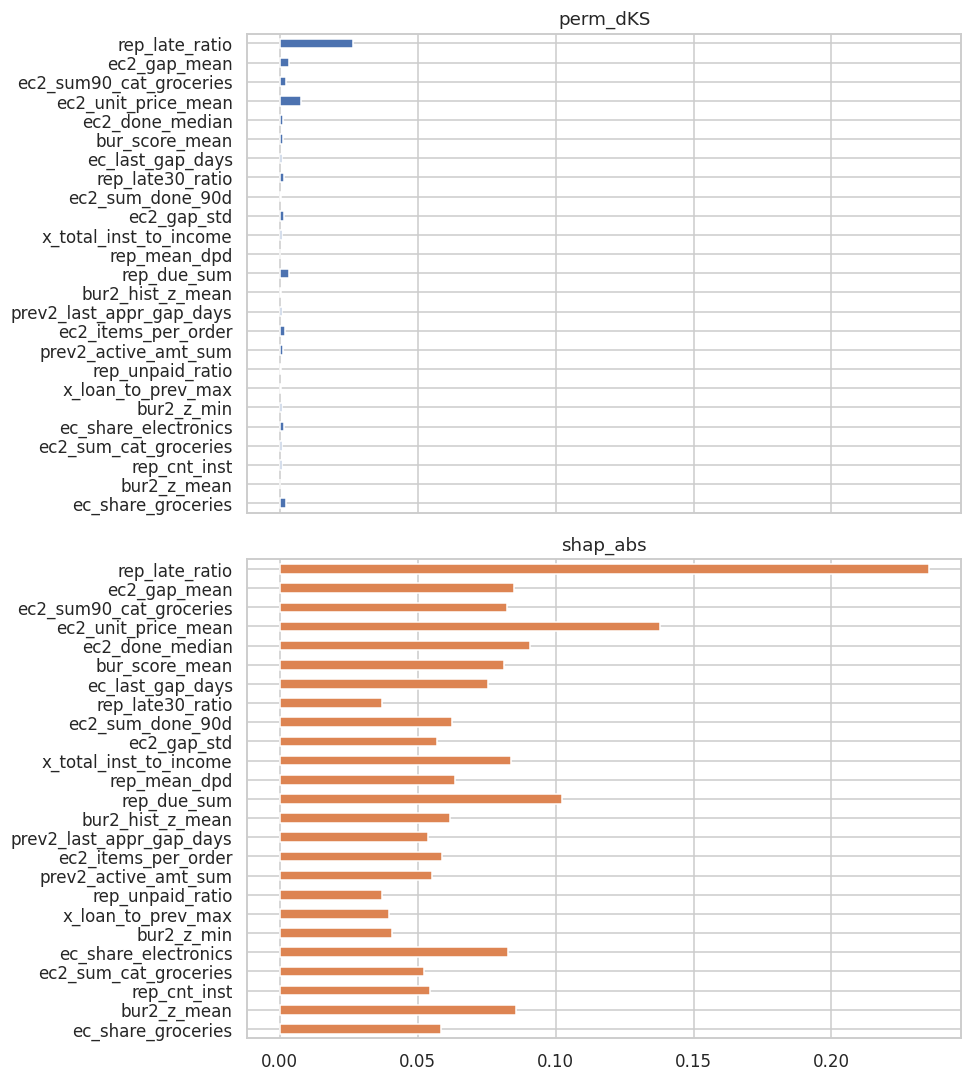

In [85]:
# [Importance] Kontribusi per grup fitur berdasarkan permutation dKS dan SHAP
if RUN_IMPORTANCE:
    g_tab = tabel.groupby('grup')[['gain_share', 'perm_dKS', 'shap_abs']].sum().sort_values('perm_dKS', ascending=False)
    display(g_tab.round(4))
    tabel.head(25)[['perm_dKS', 'shap_abs']].iloc[::-1].plot.barh(subplots=True, figsize=(9, 10), legend=False)
    plt.tight_layout(); plt.show()

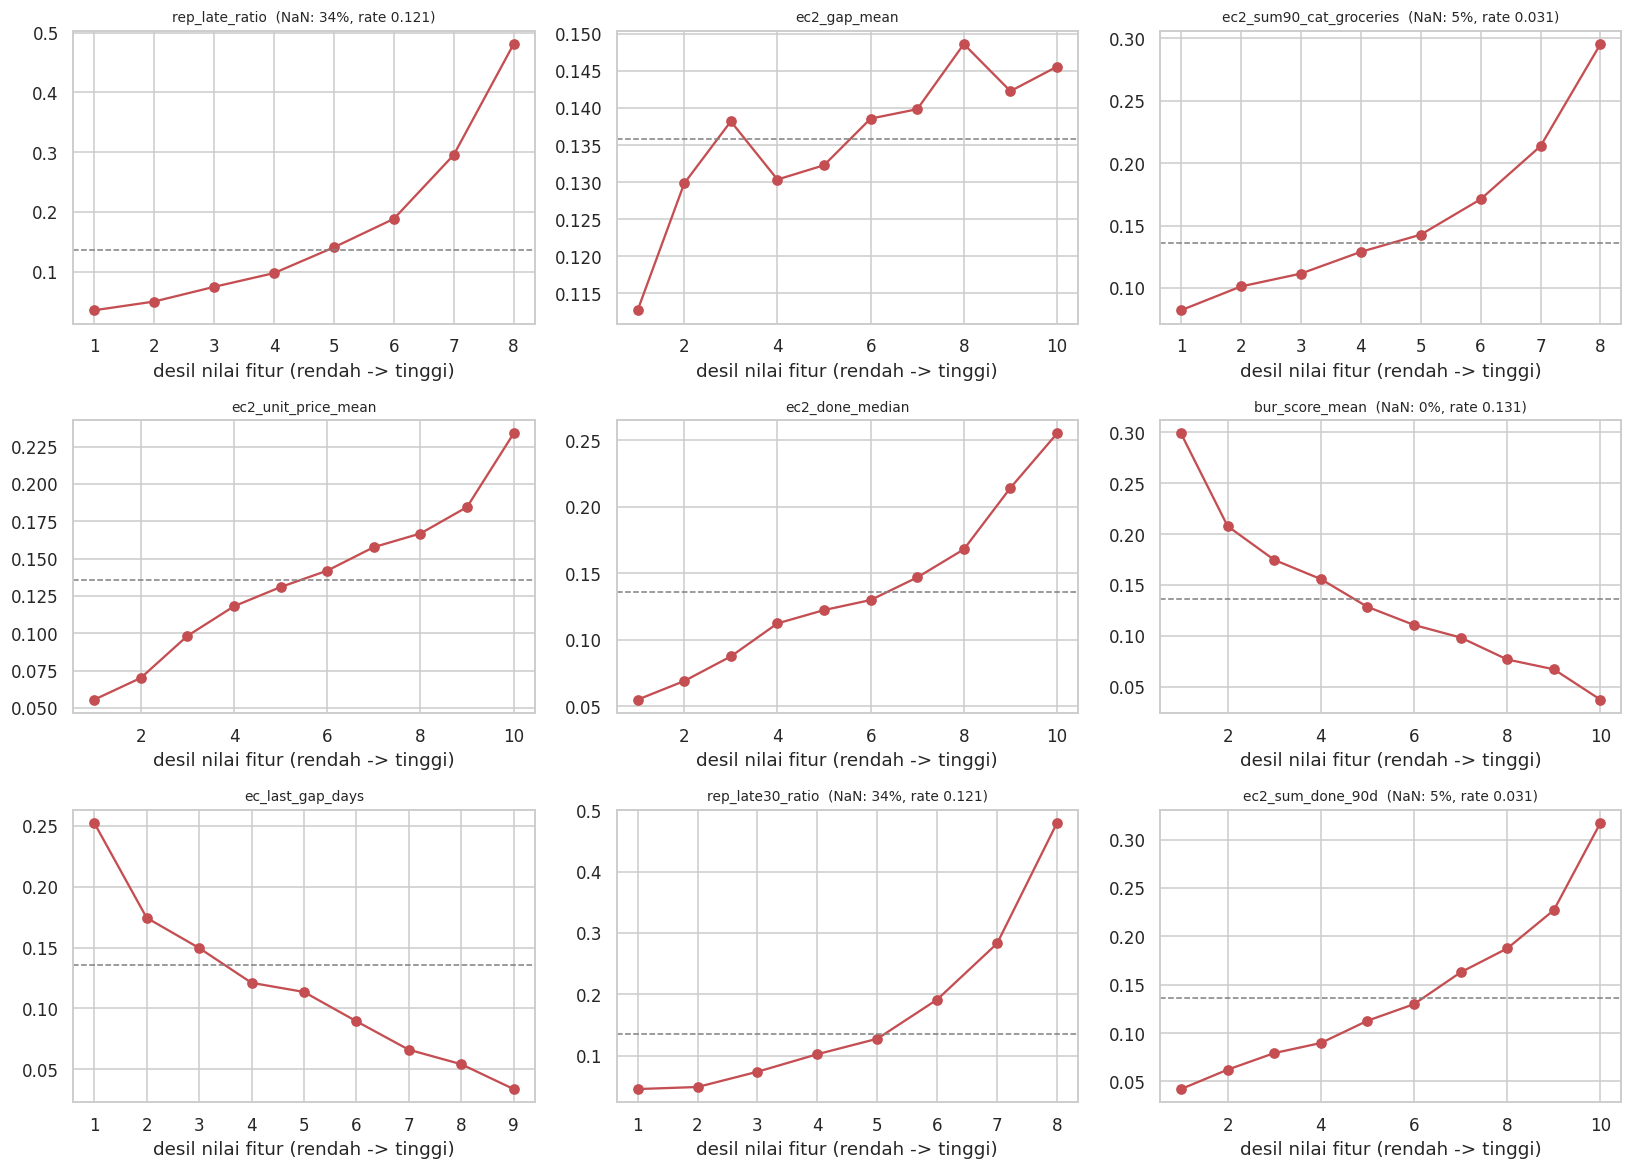

In [86]:
# [Importance] Target rate per desil untuk fitur teratas (bentuk hubungan fitur dengan target)
def plot_bin_rate(cols, X_, y_, q=10, ncols=3):
    nr = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nr, ncols, figsize=(5 * ncols, 3.6 * nr))
    axes = np.atleast_1d(axes).ravel()
    for ax, c in zip(axes, cols):
        s = pd.DataFrame({'x': X_[c].to_numpy(dtype=float), 'y': y_.to_numpy()})
        s['b'] = pd.qcut(s['x'], q, duplicates='drop')
        r = s.groupby('b', observed=True)['y'].mean()
        ax.plot(range(1, len(r) + 1), r.values, marker='o', color='#C44E52')
        ax.axhline(y_.mean(), color='gray', ls='--', lw=1)
        na = s.loc[s.x.isna(), 'y']
        ax.set_title(c + (f'  (NaN: {len(na)/len(s):.0%}, rate {na.mean():.3f})' if len(na) else ''), fontsize=9)
        ax.set_xlabel('desil nilai fitur (rendah -> tinggi)')
    for ax in axes[len(cols):]:
        ax.axis('off')
    plt.tight_layout(); plt.show()

if RUN_IMPORTANCE:
    top_num = [c for c in tabel.index if str(X[c].dtype) != 'category'][:9]
    plot_bin_rate(top_num, X, y)

In [87]:
# [Diagnostik] KS OOF per segmen riwayat (tanpa riwayat / riwayat tanpa repayment / lengkap)
seg = np.select([TRN.has_prev.values == 0, TRN.has_rep.values == 0],
                ['tanpa riwayat', 'riwayat tanpa repayment'], 'riwayat lengkap')
rows = []
for s in np.unique(seg):
    m = seg == s
    rows.append({'segmen': s, 'n': int(m.sum()), 'target_rate': y[m].mean(), 'KS': ks_score(y[m], cv['oof'][m])})
display(pd.DataFrame(rows).round(4))

,segmen,n,target_rate,KS
0,riwayat lengkap,46312,0.1431,0.5191
1,riwayat tanpa repayment,2688,0.1551,0.5072
2,tanpa riwayat,21000,0.1172,0.4755


In [88]:
# [Diagnostik] Ablasi per grup fitur: berapa KS turun jika satu grup dibuang (sekitar 1 menit per grup)
if RUN_IMPORTANCE:
    base_ks = cv['oof_ks']
    rows = []
    for g in ['ecommerce', 'bureau', 'previous', 'account', 'account_3m', 'repayment_6m', 'base']:
        cols = [c for c in AUD_FEATS if feat_group(c) != g]
        r = quick_cv(TRN[cols], y)
        rows.append({'grup_dibuang': g, 'n_fitur': len(cols), 'oof_ks': r['oof_ks'], 'delta': r['oof_ks'] - base_ks})
    display(pd.DataFrame(rows).sort_values('delta').round(4))

,grup_dibuang,n_fitur,oof_ks,delta
0,ecommerce,93,0.4227,-0.0822
1,bureau,95,0.4851,-0.0199
2,previous,99,0.4913,-0.0137
6,base,91,0.4937,-0.0113
4,account_3m,101,0.4940,-0.0110
5,repayment_6m,102,0.4953,-0.0096
3,account,100,0.4954,-0.0096


In [89]:
# [Eksperimen v1] Fungsi CV berulang (beberapa seed, fold sama untuk semua varian)
def repeat_cv(X_, y_, seeds=V1_SEEDS):
    return np.array([quick_cv(X_, y_, seed=s)['oof_ks'] for s in seeds])

In [90]:
# [Eksperimen v1] Definisi varian: v0, v0 tanpa grup noise, lalu tambah satu modul v1 per varian
TRN1 = FE1[FE1.is_train == 1]
v0_cols = [c for c in FE.columns if c not in BASE_DROP]
clean = [c for c in v0_cols if feat_group(c) not in NOISE_GROUPS and c not in NOISE_COLS]
newc = lambda p: [c for c in TRN1.columns if c.startswith(p)]
VARIANTS = {
    'V0 fitur v0 lengkap': v0_cols,
    'V1 v0 tanpa grup noise': clean,
    'V2 + ecommerce v1': clean + newc('ec2_'),
    'V3 + bureau v1': clean + newc('bur2_'),
    'V4 + repayment v1': clean + newc('rep2_'),
    'V5 + previous v1': clean + newc('prev2_'),
    'V6 semua v1 + rasio lintas tabel': clean + newc('ec2_') + newc('bur2_') + newc('rep2_') + newc('prev2_') + newc('x_'),
}
print({k: len(v) for k, v in VARIANTS.items()})

{'V0 fitur v0 lengkap': 114, 'V1 v0 tanpa grup noise': 78, 'V2 + ecommerce v1': 153, 'V3 + bureau v1': 107, 'V4 + repayment v1': 93, 'V5 + previous v1': 87, 'V6 semua v1 + rasio lintas tabel': 215}


In [91]:
# [Eksperimen v1] Jalankan semua varian (CV berulang) dan hitung selisih berpasangan terhadap V1
if RUN_V1_EXPERIMENTS:
    res_v = {k: repeat_cv(TRN1[cols], y) for k, cols in VARIANTS.items()}
    ref = res_v['V1 v0 tanpa grup noise']
    tab_v = pd.DataFrame({
        'n_fitur': {k: len(VARIANTS[k]) for k in VARIANTS},
        'ks_rata2': {k: v.mean() for k, v in res_v.items()},
        'delta_vs_V1': {k: (v - ref).mean() for k, v in res_v.items()},
        'delta_sd': {k: (v - ref).std() for k, v in res_v.items()},
        'ks_per_seed': {k: np.round(v, 4).tolist() for k, v in res_v.items()},
    })
    display(tab_v.round(4))

,n_fitur,ks_rata2,delta_vs_V1,delta_sd,ks_per_seed
V0 fitur v0 lengkap,114,0.4945,0.0007,0.0011,"[0.495, 0.493, 0.4956]"
V1 v0 tanpa grup noise,78,0.4938,0.0000,0.0000,"[0.4936, 0.4938, 0.494]"
V2 + ecommerce v1,153,0.5009,0.0071,0.0017,"[0.4994, 0.4998, 0.5035]"
V3 + bureau v1,107,0.4935,-0.0003,0.0013,"[0.493, 0.4921, 0.4954]"
V4 + repayment v1,93,0.4929,-0.0009,0.0010,"[0.4915, 0.4928, 0.4945]"
V5 + previous v1,87,0.4932,-0.0006,0.0013,"[0.4947, 0.4918, 0.4931]"
V6 semua v1 + rasio lintas tabel,215,0.5035,0.0098,0.0015,"[0.5049, 0.504, 0.5017]"
